# **У нас был план собрать как можно больше черники!** 
## ***и мы его придерживались...***

## 1. Опредили роли в команде:
DS - Матвей Ярославцев, Матвей Пазгалов \
DA - Анна Кожемякина, Руслан Саяпов, Елена Савенкова \
PM - Алексей Березин 

## 2. Выбрали репозиторий для работы:
https://github.com/matveyyaros/Project-activities-case-9

## 3. Создали архитектуру:
```
my-ml-project/
├── .python-version
├── pyproject.toml          # Зависимости и конфигурация инструментов (uv)
├── uv.lock                 # Единый lockfile для воспроизводимости
├── README.md
├── src/
│   └── my_project/         # Основной пакет с кодом
│       ├── __init__.py
│       ├── data/           # Загрузка и предобработка данных
│       ├── features/       # Построение признаков
│       ├── models/         # Определения моделей и обучение
│       ├── evaluation/     # Метрики и отчеты
│       └── serving/        # Код для инференса 
├── tests/                  # Юнит-тесты (pytest)
├── notebooks/              # Jupyter-ноутбуки (только для исследования)
├── conf/                   # Конфигурации
├── data/                   # Данные
│   ├── raw/
│   ├── interim/
│   └── processed/
├── models/                 # Обученные артефакты
└── reports/                # Сгенерированные отчеты и графики
```
## 4. Провели спринты:
Проводили сверку по задачам через zoom и обсуждали гипотезы каждую неделю + регулярная переписка в telegram

## 5. Разбили на этапы: 
I. загрузка и подготовка данных и разведочный анализ данных (EDA) \
II. построение базовых моделей, подбор гиперпараметров и тестирование \
III. проверка результатов / отчет о качестве модели


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matveyyaros/Project-activities-case-9/blob/ruslan/notebooks/EDA3.ipynb)

# **I. EDA: подготовка и анализ данных для прогноза**

**Датасет:** Wild Blueberry Pollination Simulation Data (Obsie, Qu, Drummond, University of Maine)  
https://www.kaggle.com/datasets/saurabhshahane/wild-blueberry-yield-prediction?resource=download-directory

Одна тетрадка объединяет разведочный анализ (EDA) и подготовку данных к модели. Путь сквозной: постановка задачи → осмотр и качество данных → отложенный тест → визуальный анализ и инсайты → метрика и валидация → новые признаки → предобработка → сравнение масштабирования → проверка на утечки.

**Как запускать:** в Colab — меню **Среда выполнения → Выполнить все** (Ctrl+F9). Ячейки зависят друг от друга, поэтому выполнять их нужно строго сверху вниз.

Итоговая модель обучается отдельно (конвейер `Ridge_Robust`: `RobustScaler → PolynomialFeatures(3) → RobustScaler → Ridge`). Здесь та же схема разбиения, что в модели, поэтому выводы переносятся в неё напрямую.

| Раздел | Что внутри |
|---|---|
| 1 | Постановка задачи |
| 2 | Данные и контекст |
| 3 | Первичный осмотр данных |
| 4 | Качество данных, отбор строк и столбцов, отложенная тестовая выборка |
| 5 | Одномерный анализ |
| 6 | Многомерный анализ |
| 7 | Сегментированный анализ |
| 8 | Выбор метрики качества |
| 9 | Схема валидации |
| 10 | Новые признаки и гипотезы |
| 11 | Стратегия предобработки: пропуски, кодирование, масштабирование |
| 12 | Сравнение способов масштабирования |
| 13 | Проверка на утечки данных |
| 14 | Итоги |

**Правило по данным.** До раздела 4.5 смотрим только то, что не использует урожай: типы, пропуски, дубликаты, сетку значений, выбросы во входных условиях. В разделе 4.5 откладываем тест (152 строки). Всё, где участвует `yield`, — только по обучающей части (607 строк).

---
# **1. Постановка задачи**

**Заказчик:** фермерское хозяйство, выращивающее дикую чернику.
**Вопрос заказчика:** какие условия дают самый высокий урожай черники и на что хозяйство может повлиять чтобы его улучшить (например, завезти ульи или шмелей)?

| Вопрос | Ответ |
|---|---|
| **Бизнес-вопрос** | Какой урожай даст поле черники при заданных условиях опыления и погоды? Это нужно, чтобы планировать сбор и решать, стоит ли завозить ульи |
| **Что предсказываем** | `yield` — урожай с поля |
| **Тип задачи** | **линейная регрессия** с учителем: цель — непрерывное число |
| **Один объект** | одна строка = **один сценарий** компьютерной симуляции опыления: размер клона, плотность четырёх видов пчёл, температура и дожди. Значение — среднее по 100 прогонам |
| **Признаки** | 7 факторов, известных **до сезона**: `clonesize`, `honeybee`, `bumbles`, `andrena`, `osmia`, `AverageOfUpperTRange`, `RainingDays` |
| **Ограничение** | данные синтетические, с дискретной сеткой значений (2–5 уровней у каждого фактора) — модель надёжна только внутри этой сетки |

## **Импорты и настройки**

In [15]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # шум от индикатора загрузки kagglehub

from pathlib import Path
from math import pi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler,
                                   QuantileTransformer, Normalizer, PolynomialFeatures,
                                   OneHotEncoder, TargetEncoder)
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso
from sklearn.metrics import r2_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)  # предупреждения о будущих версиях sklearn

import subprocess, sys
try:
    import phik  # добавляет метод df.phik_matrix()
except ImportError:  # в Colab phik не предустановлен
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "phik"])
    import phik
try:
    import kagglehub  # скачивание датасетов с Kaggle
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

SEED = 1911          # тот же seed, что в модели
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

---
# **2. Данные и контекст**

## **2.1 Откуда данные**

Данные не собраны в поле, а **сгенерированы моделью** Wild Blueberry Pollination Model (платформа GAMA). Модель откалибрована по 30 годам наблюдений в штате Мэн.
Проведено 77 700 прогонов симуляции, каждая из 777 строк — среднее по 100 прогонам.

**Следствие для EDA:** признаки — это заданные экспериментатором настройки, поэтому каждый принимает лишь несколько фиксированных значений (сетка эксперимента).

## **2.2 Загрузка данных**

Данные скачиваются с Kaggle: [Wild Blueberry Yield Prediction](https://www.kaggle.com/datasets/saurabhshahane/wild-blueberry-yield-prediction).
Библиотека `kagglehub` скачивает публичный датасет без регистрации и кладёт его в кэш (`~/.cache/kagglehub`), поэтому при повторном запуске файл заново не качается.
Если Kaggle недоступен (нет интернета), берём локальную копию из `data/raw/`, а если нет и её — копию из репозитория на GitHub.

In [ ]:
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

KAGGLE_DATASET = "saurabhshahane/wild-blueberry-yield-prediction"
CSV_NAME = "WildBlueberryPollinationSimulationData.csv"
DATA_PATH = ROOT / "data" / "raw" / CSV_NAME
DATA_URL = ("https://raw.githubusercontent.com/matveyyaros/Project-activities-case-9/"
            "506b161/data/raw/WildBlueberryPollinationSimulationData.csv")

try:
    kaggle_dir = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    df = pd.read_csv(next(kaggle_dir.rglob(CSV_NAME)))
    print(f"Данные скачаны с Kaggle: {KAGGLE_DATASET}")
except Exception as e:
    print(f"Kaggle недоступен ({type(e).__name__}: {e})")
    df = pd.read_csv(DATA_PATH) if DATA_PATH.exists() else pd.read_csv(DATA_URL)
    print("Данные загружены из запасного источника")
print(f"Исходная таблица: {df.shape[0]} строк × {df.shape[1]} столбцов")

### Описание столбцов (по статье Data in Brief)

| Столбец | Единицы | Описание |
|---------|---------|----------|
| **Row#** | — | Номер строки (не признак) |
| **clonesize** | м² | Средний размер клона (куста) черники в поле |
| **honeybee** | пчёл/м²/мин | Плотность медоносных пчёл |
| **bumbles** | пчёл/м²/мин | Плотность шмелей |
| **andrena** | пчёл/м²/мин | Плотность пчёл-андрен |
| **osmia** | пчёл/м²/мин | Плотность пчёл-осмий |
| **MaxOfUpperTRange** | °F | Максимум верхней границы дневной температуры за цветение |
| **MinOfUpperTRange** | °F | Минимум верхней границы дневной температуры |
| **AverageOfUpperTRange** | °F | Среднее верхней границы дневной температуры |
| **MaxOfLowerTRange** | °F | Максимум нижней границы дневной температуры |
| **MinOfLowerTRange** | °F | Минимум нижней границы дневной температуры |
| **AverageOfLowerTRange** | °F | Среднее нижней границы дневной температуры |
| **RainingDays** | дни | Число дождливых дней за цветение |
| **AverageRainingDays** | — | Доля дождливых дней за цветение |
| **fruitset** | доля | Завязываемость плодов (результат опыления) |
| **fruitmass** | г | Масса плода (результат) |
| **seeds** | шт | Число семян в ягоде (результат) |
| **yield** | — | **Урожай — целевая переменная** |

В статье температуры подписаны как ℃, но значения 39–95 возможны только в **°F**.

### Константы

Списки столбцов, которые используются во всей тетрадке. Почему выбраны именно они — в разделах 4.6 и 4.7.

In [3]:
FEATURES = ["clonesize", "honeybee", "bumbles", "andrena", "osmia", "AverageOfUpperTRange", "RainingDays"]
LEAKY = ["fruitset", "fruitmass", "seeds"]   # результаты опыления — утечка цели (раздел 4.7)
TARGET = "yield"
GRID_CLONES = [12.5, 25, 37.5]               # основная сетка эксперимента (раздел 4.4)

# Входные условия (всё, кроме Row#, результатов и цели) — их можно смотреть по всем строкам
INPUTS = [c for c in df.columns if c not in ["Row#", *LEAKY, TARGET]]
print(f"Входных столбцов: {len(INPUTS)}; используемых факторов: {len(FEATURES)}")

Входных столбцов: 13; используемых факторов: 7


---
# **3. Первичный осмотр данных**

## **3.1 Первый взгляд**

In [ ]:
df.head()

In [5]:
# Случайная выборка — смотрим разные срезы
df.sample(5, random_state=42)

,Row#,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
568,568,25.0,0.50,0.25,0.63,0.50,69.7,42.1,58.2,50.2,24.3,41.2,34.0,0.56,0.388956,0.376880,29.284336,4282.700632
530,530,25.0,0.50,0.25,0.50,0.63,77.4,46.8,64.7,55.8,27.0,45.8,1.0,0.10,0.532729,0.466475,38.060375,6801.492050
610,610,25.0,0.50,0.25,0.75,0.50,77.4,46.8,64.7,55.8,27.0,45.8,1.0,0.10,0.510669,0.452680,36.386359,6279.338501
109,109,12.5,0.25,0.25,0.25,0.63,69.7,42.1,58.2,50.2,24.3,41.2,16.0,0.26,0.546136,0.453001,37.970243,6898.390949
586,586,25.0,0.50,0.25,0.63,0.75,86.0,52.0,71.9,62.0,30.0,50.8,1.0,0.10,0.542164,0.471829,38.705696,7004.015537


## **3.2 Технический паспорт**

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 777 entries, 0 to 776
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Row#                  777 non-null    int64  
 1   clonesize             777 non-null    float64
 2   honeybee              777 non-null    float64
 3   bumbles               777 non-null    float64
 4   andrena               777 non-null    float64
 5   osmia                 777 non-null    float64
 6   MaxOfUpperTRange      777 non-null    float64
 7   MinOfUpperTRange      777 non-null    float64
 8   AverageOfUpperTRange  777 non-null    float64
 9   MaxOfLowerTRange      777 non-null    float64
 10  MinOfLowerTRange      777 non-null    float64
 11  AverageOfLowerTRange  777 non-null    float64
 12  RainingDays           777 non-null    float64
 13  AverageRainingDays    777 non-null    float64
 14  fruitset              777 non-null    float64
 15  fruitmass             777 non-null

### Анализ `.info()`:

| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | все числовые (float64 + int64 для Row#) | Категориальных столбцов нет |
| **Пропуски** | non-null = 777 во всех столбцах | Пропусков нет |

## **3.3 Оптимизация памяти**

In [7]:
# Считаем на копии: основная таблица остаётся в float64, чтобы результаты совпадали с моделью
df_small = df.copy()
memory_before = df_small.memory_usage(deep=True).sum() / 1024
print(f"Память до: {memory_before:.1f} KB")

for col in df_small.select_dtypes(include="int64").columns:
    df_small[col] = pd.to_numeric(df_small[col], downcast="integer")
for col in df_small.select_dtypes(include="float64").columns:
    df_small[col] = pd.to_numeric(df_small[col], downcast="float")

memory_after = df_small.memory_usage(deep=True).sum() / 1024
print(f"Память после: {memory_after:.1f} KB (экономия {(1 - memory_after / memory_before) * 100:.0f}%)")

Память до: 109.4 KB
Память после: 53.2 KB (экономия 51%)


Датасет крошечный (777 строк), поэтому оптимизация здесь — скорее упражнение. Для расчётов дальше оставляем исходную таблицу в float64: тогда цифры точно совпадают с моделью коллег.

## **3.4 Статистическая сводка**

До разбиения на обучение и тест смотрим **только входные условия**. Описание урожая и результатов опыления — в разделе 5, по обучающей части: так тест не участвует ни в одном решении.

In [8]:
df[INPUTS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
clonesize,777.0,18.768,6.999,10.00,12.50,12.50,25.00,40.000
honeybee,777.0,0.417,0.979,0.00,0.25,0.25,0.50,18.430
bumbles,777.0,0.282,0.066,0.00,0.25,0.25,0.38,0.585
andrena,777.0,0.469,0.161,0.00,0.38,0.50,0.63,0.750
osmia,777.0,0.562,0.169,0.00,0.50,0.63,0.75,0.750
MaxOfUpperTRange,777.0,82.277,9.194,69.70,77.40,86.00,89.00,94.600
MinOfUpperTRange,777.0,49.701,5.596,39.00,46.80,52.00,52.00,57.200
AverageOfUpperTRange,777.0,68.723,7.677,58.20,64.70,71.90,71.90,79.000
MaxOfLowerTRange,777.0,59.309,6.648,50.20,55.80,62.00,66.00,68.200
MinOfLowerTRange,777.0,28.690,3.210,24.30,27.00,30.00,30.00,33.000


**Что бросается в глаза:**
- `honeybee`: среднее 0.42, а максимум 18.43 — очень длинный правый хвост.
- У большинства признаков медиана совпадает с квартилями (например, `clonesize`: 25% = медиана = 12.5) — признак принимает мало значений.

## **3.5 Сетка эксперимента: число уникальных значений**

In [9]:
nunique = df.drop(columns='Row#').nunique().sort_values()
nunique.to_frame('Уникальных значений')

,Уникальных значений
MaxOfLowerTRange,5
AverageRainingDays,5
RainingDays,5
AverageOfLowerTRange,5
MinOfLowerTRange,5
MaxOfUpperTRange,5
MinOfUpperTRange,5
AverageOfUpperTRange,5
clonesize,6
honeybee,7


In [10]:
# Какие именно значения принимают «настроечные» признаки
for col in ['clonesize', 'honeybee', 'RainingDays', 'AverageOfUpperTRange']:
    print(f"{col}:")
    print(df[col].value_counts().sort_index().to_string(), "\n")

clonesize:
clonesize
10.0      1
12.5    406
20.0     16
25.0    328
37.5     25
40.0      1 

honeybee:
honeybee
0.000       8
0.250     446
0.500     302
0.537       6
0.750      11
6.640       2
18.430      2 

RainingDays:
RainingDays
1.00     192
3.77      16
16.00    194
24.00    188
34.00    187 

AverageOfUpperTRange:
AverageOfUpperTRange
58.2    181
64.7    188
65.6      2
71.9    212
79.0    194 



### **Важное наблюдение:** это не наблюдения, а план эксперимента

| Группа | Уникальных значений | Смысл |
|--------|--------------------|-------|
| Температуры, дожди | 5 | 5 «сценариев погоды» |
| `clonesize` | 6 | в основном 12.5, 25 и 37.5 |
| Пчёлы | 7–12 | несколько уровней плотности |
| `fruitset`, `fruitmass`, `seeds`, `yield` | ~777 | **результаты** симуляции |

---
# **4. Качество данных, отбор строк и столбцов, отложенная тестовая выборка**

## **4.1 Пропуски**

In [11]:
missing = df.isna().sum()
print(f"Всего пропусков: {missing.sum()}")

Всего пропусков: 0


**Вывод:** пропусков нет — симуляция выдаёт полную таблицу. Стратегия на случай полевых данных с пропусками — в разделе 11.1.

## **4.2 Дубликаты**

In [12]:
features_in = ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia',
               'MaxOfUpperTRange', 'MinOfUpperTRange', 'AverageOfUpperTRange',
               'MaxOfLowerTRange', 'MinOfLowerTRange', 'AverageOfLowerTRange',
               'RainingDays', 'AverageRainingDays']

print(f"Полных дубликатов (без Row#): {df.drop(columns='Row#').duplicated().sum()}")
print(f"Строк с одинаковыми входными условиями: {df.duplicated(subset=features_in).sum()}")

Полных дубликатов (без Row#): 0
Строк с одинаковыми входными условиями: 0


**Вывод:** дубликатов нет — каждая строка соответствует своей комбинации условий. После разбиения та же проверка повторяется для обучающей и тестовой частей (раздел 13.3).

## **4.3 Выбросы**

### Визуальный метод: boxplot

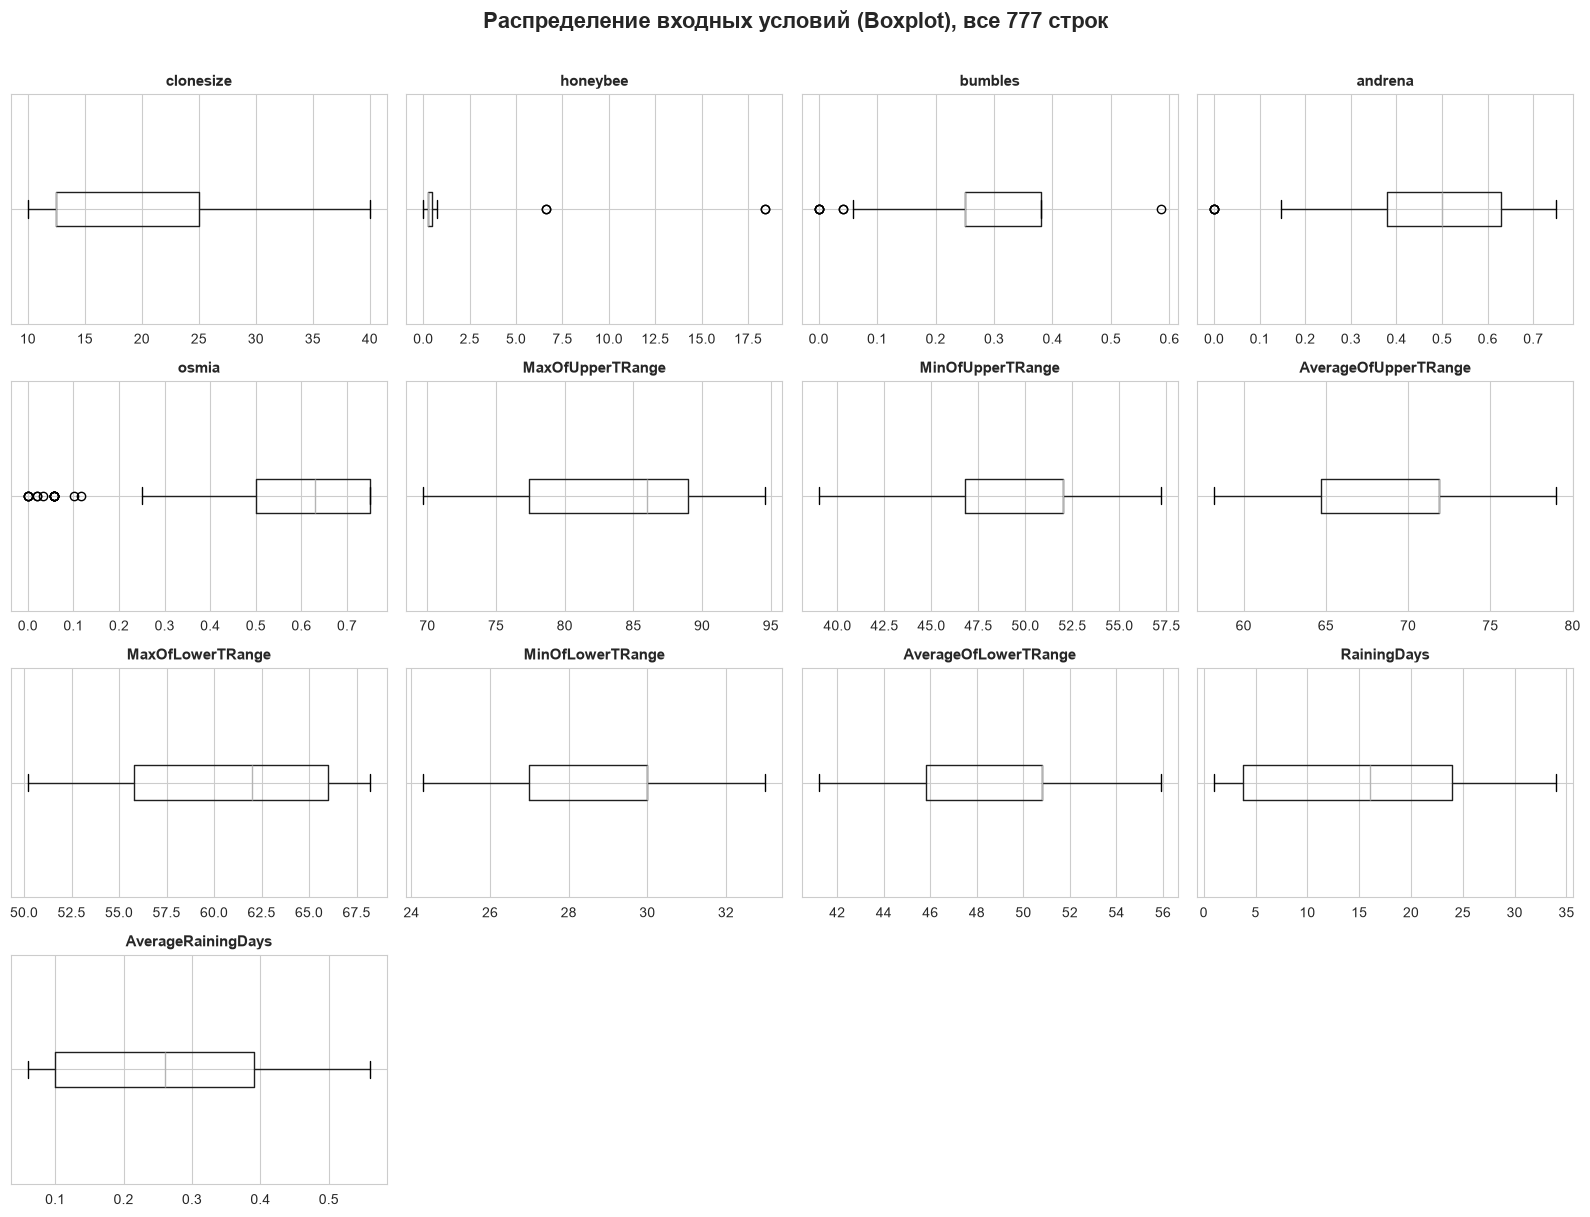

In [13]:
plot_cols = INPUTS  # урожай и результаты опыления — в разделе 5, по обучающей части

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.flatten(), plot_cols):
    df.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_yticklabels([])
for ax in axes.flatten()[len(plot_cols):]:
    ax.set_visible(False)

plt.suptitle('Распределение входных условий (Boxplot), все 777 строк', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Анализ выбросов

| Признак | Что видно | Интерпретация |
|---------|-----------|---------------|
| **honeybee** | Значения 6.64 и 18.43 | Сценарии «привезли ульи» — экстремальная плотность пчёл |
| **bumbles, andrena, osmia** | Точки около 0 | Сценарии без отдельных видов опылителей |

Низкие значения урожая и завязи смотрим в разделе 5 — уже только по обучающей части.

### Проверка аномалий

In [14]:
bees = ['honeybee', 'bumbles', 'andrena', 'osmia']
show = ['Row#'] + INPUTS  # без урожая: тест ещё не отложен

extreme_honeybee = df[df['honeybee'] > 1]
print(f"Строк с honeybee > 1: {len(extreme_honeybee)}")
display(extreme_honeybee[show])

zero_bees = df[(df[bees] == 0).any(axis=1)]
print(f"\nСтрок, где хотя бы один вид пчёл = 0: {len(zero_bees)}")
display(zero_bees[show])

Строк с honeybee > 1: 4


,Row#,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays
761,761,20.0,6.64,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
762,762,20.0,18.43,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
763,763,20.0,6.64,0.065,0.229,0.033,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
765,765,20.0,18.43,0.042,0.147,0.021,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06



Строк, где хотя бы один вид пчёл = 0: 10


,Row#,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays
759,759,20.0,0.00,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
760,760,20.0,0.00,0.202,0.707,0.101,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
761,761,20.0,6.64,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
762,762,20.0,18.43,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
766,766,20.0,0.00,0.042,0.147,0.021,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
767,767,20.0,0.00,0.585,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
768,768,20.0,0.00,0.000,0.585,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
769,769,20.0,0.00,0.000,0.000,0.585,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
770,770,20.0,0.00,0.293,0.234,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06
771,771,20.0,0.00,0.058,0.409,0.117,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06


Все аномальные строки собраны в **конце файла** (Row# ≥ 759) и выглядят как отдельная серия экспериментов. Проверим, чем этот блок отличается от остальных.

In [15]:
# Основная сетка эксперимента — clonesize 12.5, 25 и 37.5
main_grid = df['clonesize'].isin(GRID_CLONES)
special = df[~main_grid]

print(f"Основная сетка: {main_grid.sum()} строк")
print(f"Особый блок: {len(special)} строк, Row# {special['Row#'].min()}–{special['Row#'].max()}")
print("\nЗначения в особом блоке:")
for col in ['clonesize', 'RainingDays', 'AverageOfUpperTRange']:
    print(f"  {col}: {sorted(special[col].unique().tolist())}")

Основная сетка: 759 строк
Особый блок: 18 строк, Row# 759–776

Значения в особом блоке:
  clonesize: [10.0, 20.0, 40.0]
  RainingDays: [3.77, 24.0]
  AverageOfUpperTRange: [65.6, 71.9]


## **4.4 Особый блок: почему убираем 18 строк**

Основные 759 строк — это **сетка**: у каждого признака 2–5 заранее выбранных значений, перебираются их сочетания (клон 12.5 / 25 / 37.5; медоносные пчёлы 0.25 / 0.5 / 0.75; шмели 0.25 / 0.38; андрены и осмии 0.25 … 0.75; температура 58.2 / 64.7 / 71.9 / 79.0 °F; дожди 1 / 16 / 24 / 34 дня).

18 строк — отдельный эксперимент **«а что если поменять одно»**: взяли одно типичное поле (`Row#` 764) и меняли у него по одному-два параметра. Данные корректны, но к сетке не относятся. Ниже — все 18 строк и то, какие их значения не встречаются в сетке.

In [16]:
grid = df[df["clonesize"].isin(GRID_CLONES)]
cols = ["Row#", "clonesize", "honeybee", "bumbles", "andrena", "osmia",
        "AverageOfUpperTRange", "RainingDays", "yield"]
block = df.loc[~df["clonesize"].isin(GRID_CLONES), cols].sort_values("Row#").reset_index(drop=True)

# что поменяли у типичного поля (Row# 764) и чего нет в основной сетке
changes = {
    759: "убрали медоносных пчёл → 0 медоносных",
    760: "убрали медоносных, диких больше → шмели 0.20, андрены 0.71",
    761: "6.64 медоносных, диких нет → в 9 раз выше максимума сетки",
    762: "18.43 медоносных, диких нет → в 25 раз выше максимума",
    763: "6.64 медоносных, диких меньше",
    764: "ничего — это само типичное поле (клон 20, 3.77 дня дождей)",
    765: "18.43 медоносных, диких меньше",
    766: "почти нет пчёл → урожай 1 638, ниже любого в сетке",
    767: "только шмели 0.585 при максимуме сетки 0.38",
    768: "только андрены",
    769: "только осмии",
    770: "нет медоносных, другая смесь диких",
    771: "нет медоносных, другая смесь диких",
    772: "клон 10 — меньше минимума сетки 12.5",
    773: "клон 40 — больше максимума сетки 37.5",
    774: "дожди 24 дня (клон и пчёлы — не из сетки)",
    775: "температура 65.6 °F — нет в сетке",
    776: "65.6 °F и 24 дня дождей",
}
block["что поменяли"] = block["Row#"].map(changes)
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(block)

,Row#,clonesize,honeybee,bumbles,andrena,osmia,AverageOfUpperTRange,RainingDays,yield,что поменяли
0,759,20.0,0.000,0.117,0.409,0.058,71.9,3.77,3923.906282,убрали медоносных пчёл → 0 медоносных
1,760,20.0,0.000,0.202,0.707,0.101,71.9,3.77,5718.408168,"убрали медоносных, диких больше → шмели 0.20, андрены 0.71"
2,761,20.0,6.640,0.000,0.000,0.000,71.9,3.77,4936.364770,"6.64 медоносных, диких нет → в 9 раз выше максимума сетки"
3,762,20.0,18.430,0.000,0.000,0.000,71.9,3.77,6131.309380,"18.43 медоносных, диких нет → в 25 раз выше максимума"
4,763,20.0,6.640,0.065,0.229,0.033,71.9,3.77,5686.121958,"6.64 медоносных, диких меньше"
5,764,20.0,0.537,0.117,0.409,0.058,71.9,3.77,4225.961314,"ничего — это само типичное поле (клон 20, 3.77 дня дождей)"
6,765,20.0,18.430,0.042,0.147,0.021,71.9,3.77,6276.410544,"18.43 медоносных, диких меньше"
7,766,20.0,0.000,0.042,0.147,0.021,71.9,3.77,1637.704022,"почти нет пчёл → урожай 1 638, ниже любого в сетке"
8,767,20.0,0.000,0.585,0.000,0.000,71.9,3.77,7575.801245,только шмели 0.585 при максимуме сетки 0.38
9,768,20.0,0.000,0.000,0.585,0.000,71.9,3.77,2605.696759,только андрены


In [17]:
# Что будет, если оставить блок: модель коллег на всех 777 строках, тот же split и seed.
# Это иллюстрация решения; само правило отбора (по clonesize) урожай не использует.

def r2_on(frame):
    tr, te = train_test_split(frame, test_size=0.2, random_state=SEED)
    m = make_pipeline(RobustScaler(), PolynomialFeatures(3, include_bias=False), RobustScaler(), Ridge(alpha=0.5))
    m.fit(tr[FEATURES], tr[TARGET])
    return r2_score(te[TARGET], m.predict(te[FEATURES]))

print(f"R² на тесте с блоком  (777 строк): {r2_on(df):.2f}")
print(f"R² на тесте без блока (759 строк): {r2_on(df[df['clonesize'].isin(GRID_CLONES)]):.2f}")
print(f"Куб max honeybee: блок {block['honeybee'].max()**3:,.0f} против сетки {grid['honeybee'].max()**3:.2f}")

R² на тесте с блоком  (777 строк): -3.66
R² на тесте без блока (759 строк): 0.96
Куб max honeybee: блок 6,260 против сетки 0.42


**Общее для всех 18:** размер клона 10, 20 или 40 — такого нет ни в одной строке сетки. У большинства вне сетки ещё и дожди (3.77 дня).

**Пять причин убрать блок:**
1. **Другой эксперимент.** Сетка отвечает на вопрос «как всё влияет вместе», блок — «что будет, если у одного поля поменять одну вещь». Смешивать их — как сложить в одну таблицу два опроса с разными вопросами.
2. **Каждая ситуация встречается один раз.** 18.43 медоносных пчёл — две строки, клон 40 — одна. По одной строке модель ничему не научится, а подстраиваться под неё будет.
3. **Значения далеко за пределами сетки.** 18 ульев против максимума 0.75, полное отсутствие пчёл против минимума 0.25. Для полиномов это опасно: куб от 18.43 ≈ 6 260, куб от 0.75 ≈ 0.42 — одна строка «перетягивает» всю модель.
4. **Это видно в цифрах.** Модель коллег на всех 777 строках получает на тесте R² ≈ **−3.66** — хуже, чем всегда предсказывать среднее. Без блока — R² ≈ **0.96**.
5. **Отбор без подглядывания в урожай.** Строки отбираются только по `clonesize`, поэтому утечки нет, и то же правило применимо к новым данным.

**Цена решения:** модель не умеет отвечать на вопросы блока («что будет без пчёл», «что даст 18 ульев», «клон 40»). Её прогнозы надёжны только внутри сетки — это ограничение стоит прямо назвать в отчёте.

**Наш выбор:** анализ и модель — только по сетке (`data`, 759 строк). Особый блок остаётся в `df` для справки.

In [18]:
data = df[df['clonesize'].isin(GRID_CLONES)].drop(columns='Row#').reset_index(drop=True)
print(f"Основная сетка (data): {len(data)} строк")

Основная сетка (data): 759 строк


## **4.5 Отложенная тестовая выборка**

Разбиваем **до** любого анализа, где участвует урожай. Схема та же, что в модели: 20 %, `random_state=1911`.

In [19]:
train, test = train_test_split(data, test_size=0.2, random_state=SEED)
train = train.copy()  # в разделе 7.2 временно добавим столбец is_high

assert set(train.index).isdisjoint(test.index), "строки теста попали в обучение"
assert train[FEATURES].merge(test[FEATURES], how="inner").empty, "одинаковые сценарии в train и test"

X, y = train[FEATURES], train[TARGET]
print(f"Обучение: {len(train)} строк | Тест: {len(test)} строк — тест дальше не используется")

Обучение: 607 строк | Тест: 152 строк — тест дальше не используется


**С этого места `test` не открываем.** Все графики, гипотезы и сравнения — только на `train` (607 строк). Тест нужен один раз — для финальной оценки уже обученной модели. Так решения о признаках и предобработке не «подсматривают» в тест.

## **4.6 Избыточные признаки (мультиколлинеарность)**

Шесть температурных столбцов и два столбца про дожди описывают одно и то же. Проверим.

In [20]:
temp_cols = ['MaxOfUpperTRange', 'MinOfUpperTRange', 'AverageOfUpperTRange',
             'MaxOfLowerTRange', 'MinOfLowerTRange', 'AverageOfLowerTRange']

print(f"Минимальная корреляция между температурами: {train[temp_cols].corr().min().min():.3f}")
print(f"Корреляция RainingDays и AverageRainingDays: {train['RainingDays'].corr(train['AverageRainingDays']):.3f}")

Минимальная корреляция между температурами: 1.000
Корреляция RainingDays и AverageRainingDays: 0.992


**Вывод:** все температуры коррелируют почти на 100% — это **один** фактор «тёплый/холодный сезон». Дожди — тоже один фактор.
Для анализа оставляем по одному представителю: `AverageOfUpperTRange` и `RainingDays`.

## **4.7 Утечка целевой переменной**

`fruitset`, `fruitmass` и `seeds` — это **результаты** той же симуляции, что и `yield`. Их нельзя использовать как «причины» урожая: на момент планирования сезона они неизвестны.

In [21]:
outcomes = LEAKY
train[outcomes + ['yield']].corr()['yield'].round(3)

fruitset     0.986
fruitmass    0.940
seeds        0.971
yield        1.000
Name: yield, dtype: float64

In [22]:
# Факторы, на которые опираемся дальше — те же 7, что FEATURES
factors = FEATURES

### Итог отбора столбцов

- `Row#` — номер строки, не свойство поля → удаляем;
- 5 дублей температуры и `AverageRainingDays` — почти точные копии `AverageOfUpperTRange` и `RainingDays` (корреляция ≈ 1) → удаляем;
- `fruitset`, `fruitmass`, `seeds` — измеряются **во время сбора урожая**, до сезона их нет → **утечка цели**, удаляем (проверка кодом — раздел 13.1).

Остаются 7 факторов `FEATURES`, известных до сезона.

### Какой набор данных использовать
- **train + factors** — для поиска причин урожая.
- **train + outcomes** — для понимания механизма (урожай = завязь × масса ягоды).
- **df** — если нужны экстремальные сценарии с пчёлами (только для справки, в модель не идут).
- **test** — не трогаем: он нужен только для финальной оценки модели.

---
# **5. Одномерный анализ**

Дальше — только обучающая часть `train` (607 строк).

## **5.1 Распределение урожая (целевая переменная)**

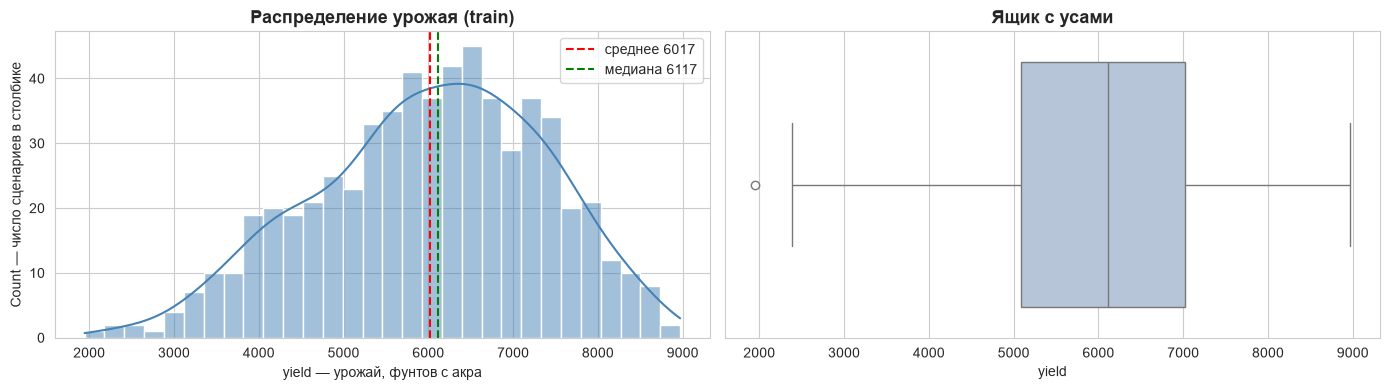

,count,mean,std,min,25%,50%,75%,max
yield,607.0,6017.0,1348.0,1946.0,5086.0,6117.0,7024.0,8969.0


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(y, bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(y.mean(), color="red", linestyle="--", label=f"среднее {y.mean():.0f}")
axes[0].axvline(y.median(), color="green", linestyle="--", label=f"медиана {y.median():.0f}")
axes[0].set_title("Распределение урожая (train)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Count — число сценариев в столбике")
axes[0].set_xlabel("yield — урожай, фунтов с акра")
axes[0].legend()
sns.boxplot(x=y, color="lightsteelblue", ax=axes[1])
axes[1].set_title("Ящик с усами", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
y.describe().round(0).to_frame().T

**Как читать графики**

*Левый — гистограмма.*
- Ось X (`yield`) — урожай. Весь диапазон разбит на 30 равных отрезков шириной ≈ 235 фунтов с акра, каждый отрезок — один столбик.
- Ось Y (**`Count`**) — **сколько строк (сценариев) из обучающей части попало в этот отрезок**. Например, столбик высотой 45 около 6 500 значит: в 45 сценариях урожай оказался примерно от 6 400 до 6 650. Сумма высот всех столбиков равна 607 — числу строк в `train`.
- Синяя плавная линия — сглаженная форма того же распределения (KDE), чтобы видеть общую «горку» без зубцов отдельных столбиков.
- Красный и зелёный пунктир — среднее и медиана (значение, которое делит сценарии пополам).

*Правый — ящик с усами.* Ящик — середина данных: половина сценариев с урожаем примерно от 5 100 до 7 000; черта внутри — медиана. Усы тянутся до самых дальних «обычных» значений, точка слева — сценарий, который заметно ниже остальных.

*Таблица под графиками.* `count` = 607 — сколько всего строк в `train` (это то же, что сумма высот столбиков); `mean` — среднее; `std` — типичное отклонение от среднего; `min`/`max` — крайние значения; `25%`, `50%`, `75%` — урожай, ниже которого четверть, половина и три четверти сценариев (`50%` — медиана).

**Что видно:**
- Урожай от ~1 950 до ~8 970, **нулей и отрицательных значений нет**, среднее ≈ медиане.
- Слабый «хвост» влево: неудачные сценарии (много дождей + жара) дают урожай вдвое ниже обычного. Это не ошибки, а реальные плохие сезоны — удалять их нельзя.
- Эти свойства понадобятся при выборе метрики (раздел 8).

## **5.2 Распределение факторов**

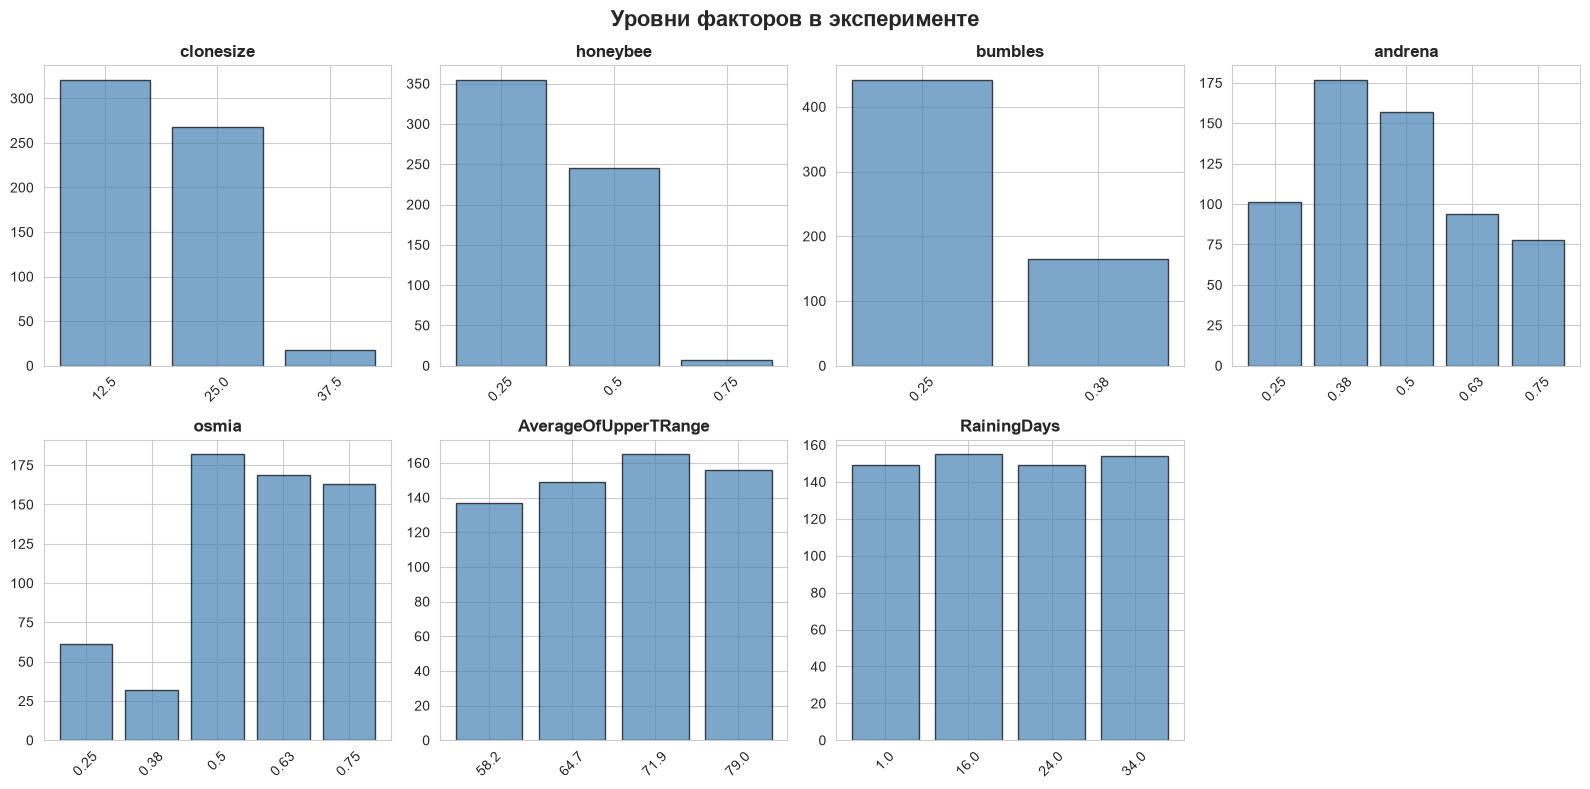

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), factors):
    counts = train[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
axes.flatten()[-1].set_visible(False)

plt.suptitle('Уровни факторов в эксперименте', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Факторы дискретные, поэтому вместо гистограмм — столбики по уровням.
Уровни встречаются **неравномерно**: например, `clonesize = 37.5` — в train всего 18 строк. Выводы по редким уровням менее надёжны. Как этот клон распределяется по фолдам кросс-валидации — в разделе 9, как кодировать уровни — в разделе 11.2.

## **5.3 Распределение результатов опыления**

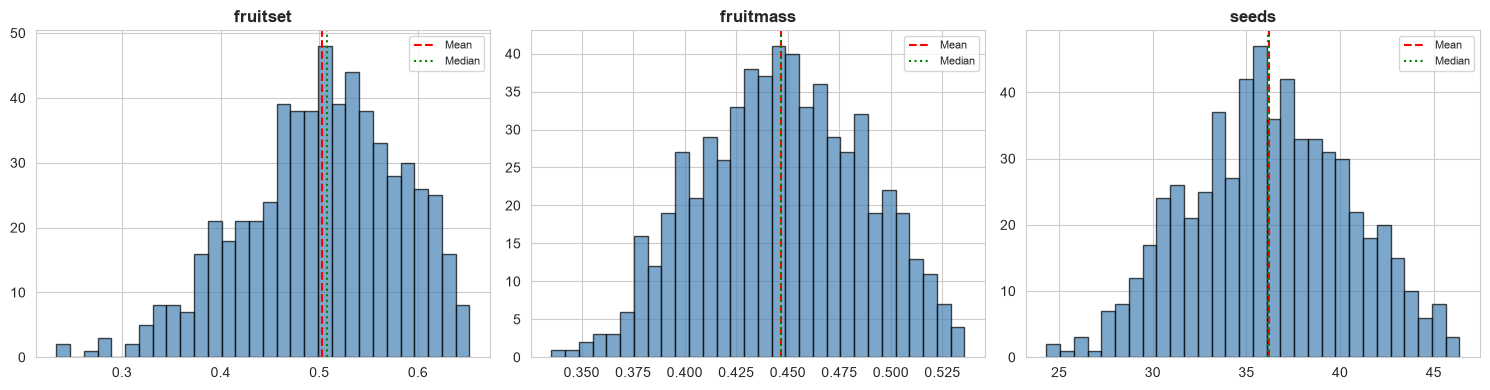

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, outcomes):
    train[col].hist(bins=30, ax=ax, color='steelblue', edgecolor='black', alpha=0.7)
    ax.axvline(train[col].mean(), color='red', linestyle='--', label='Mean')
    ax.axvline(train[col].median(), color='green', linestyle=':', label='Median')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
# **6. Многомерный анализ**

## **6.1 Визуальный анализ (pairplot)**

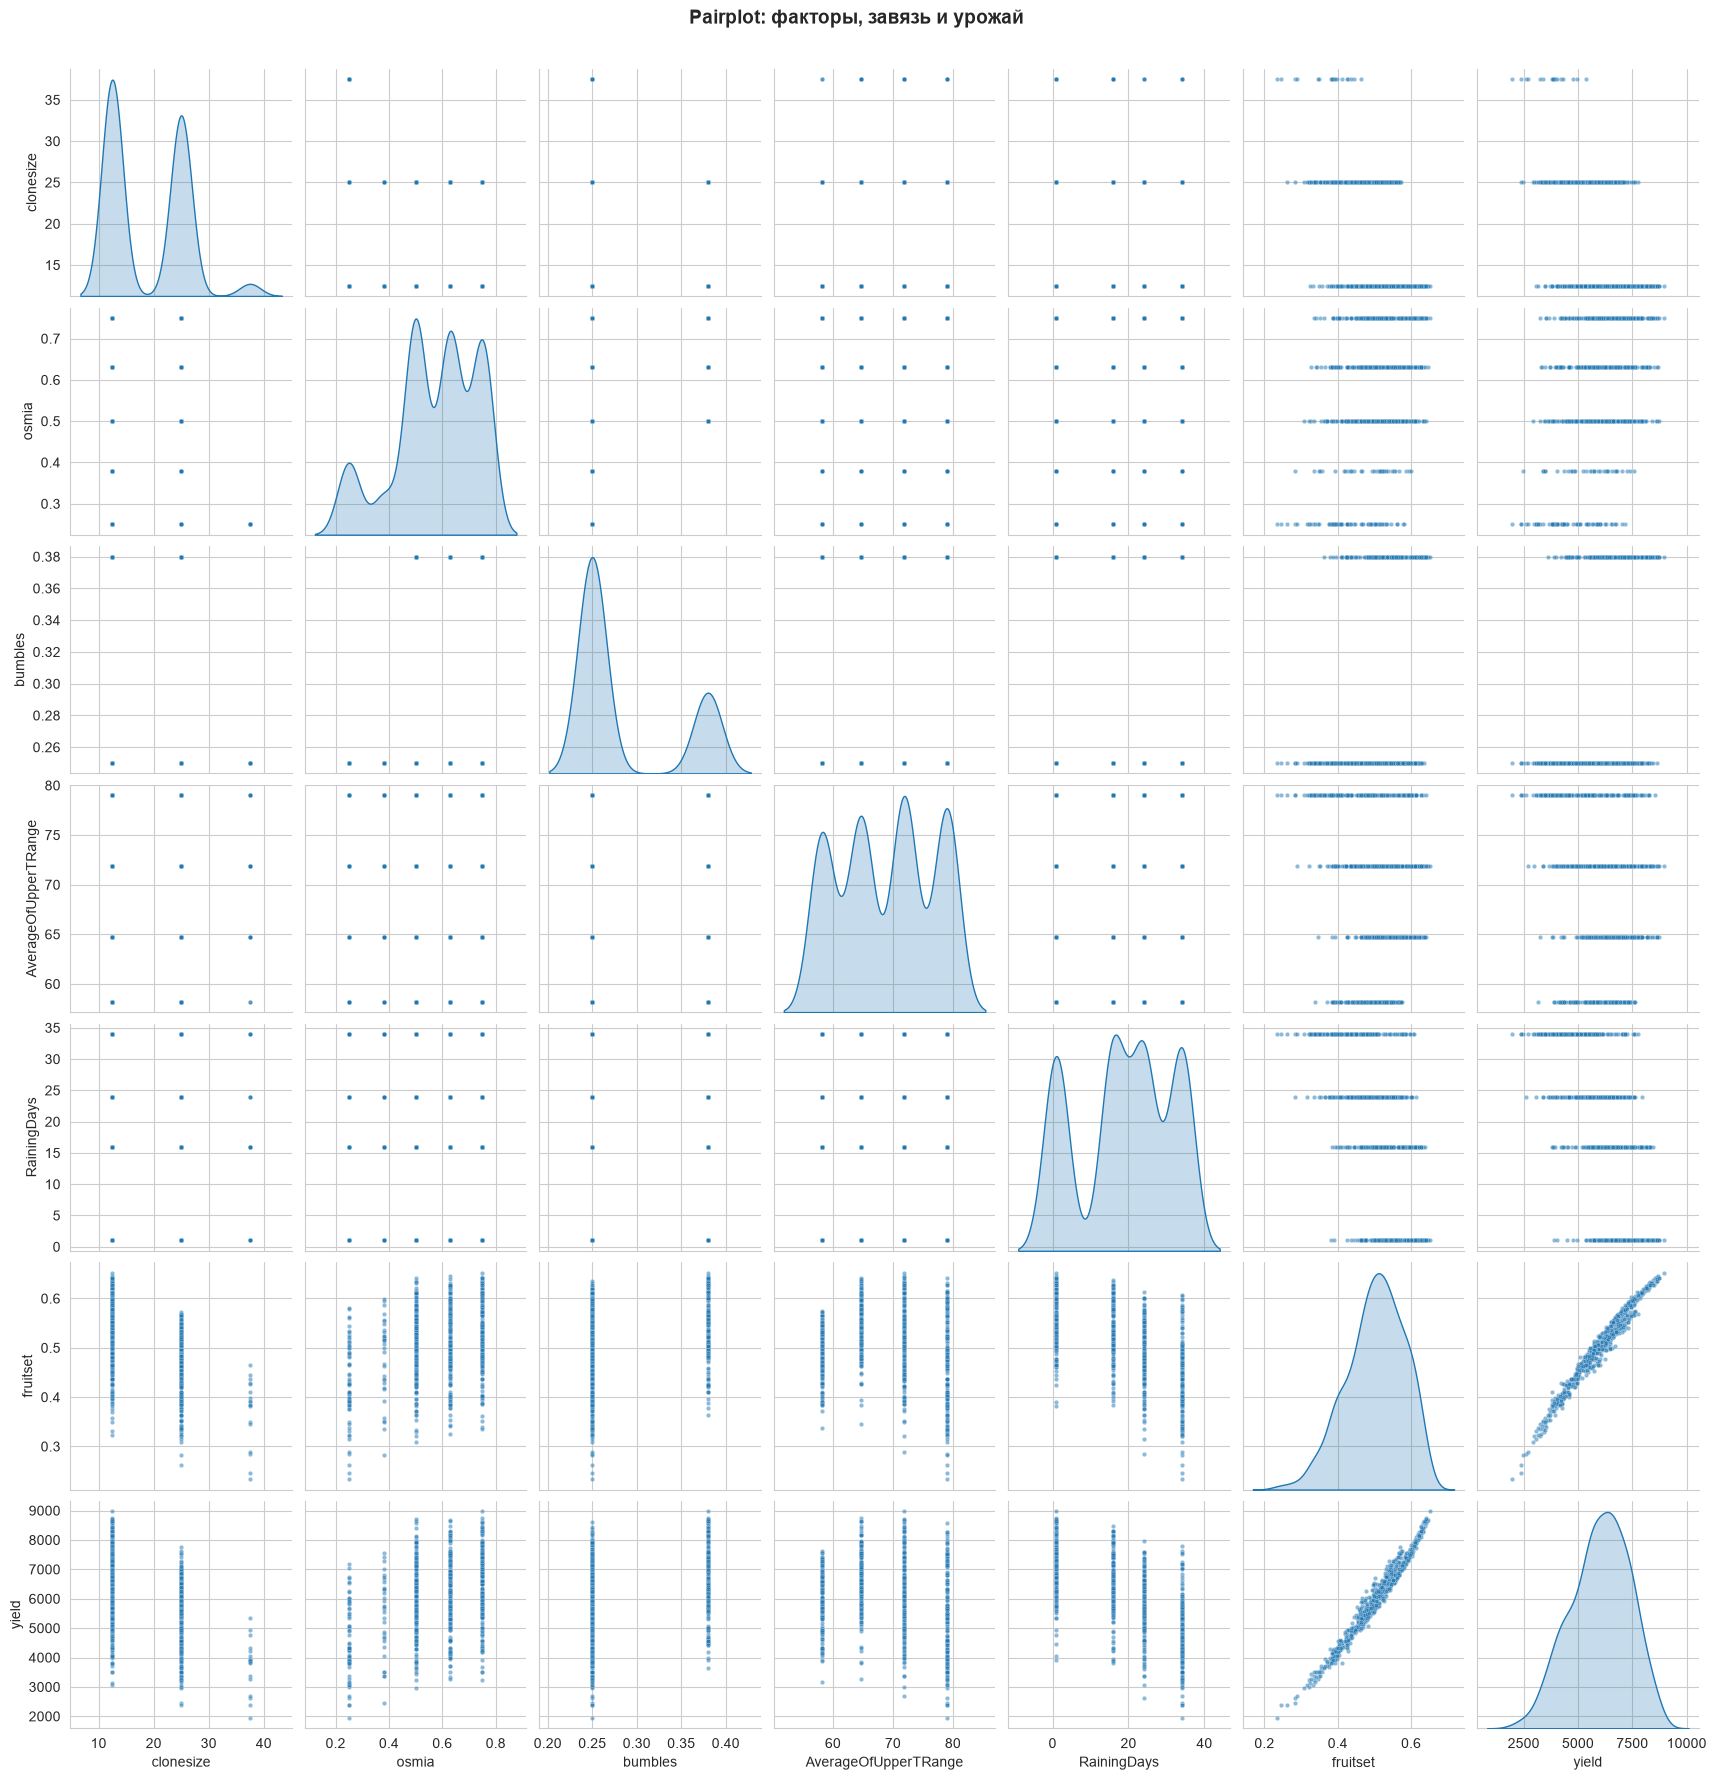

In [26]:
sns.pairplot(train[['clonesize', 'osmia', 'bumbles', 'AverageOfUpperTRange',
                       'RainingDays', 'fruitset', 'yield']],
             diag_kind='kde', plot_kws={'alpha': 0.5, 's': 10})
plt.suptitle('Pairplot: факторы, завязь и урожай', fontsize=14, fontweight='bold', y=1.02)
plt.show()

- `fruitset` и `yield` лежат почти на прямой — урожай почти полностью определяется завязью.
- По факторам точки выстроены «столбиками» (уровни эксперимента); видно, что больше дождей и крупнее клон → ниже урожай.

## **6.2 Как каждый фактор влияет на урожай**

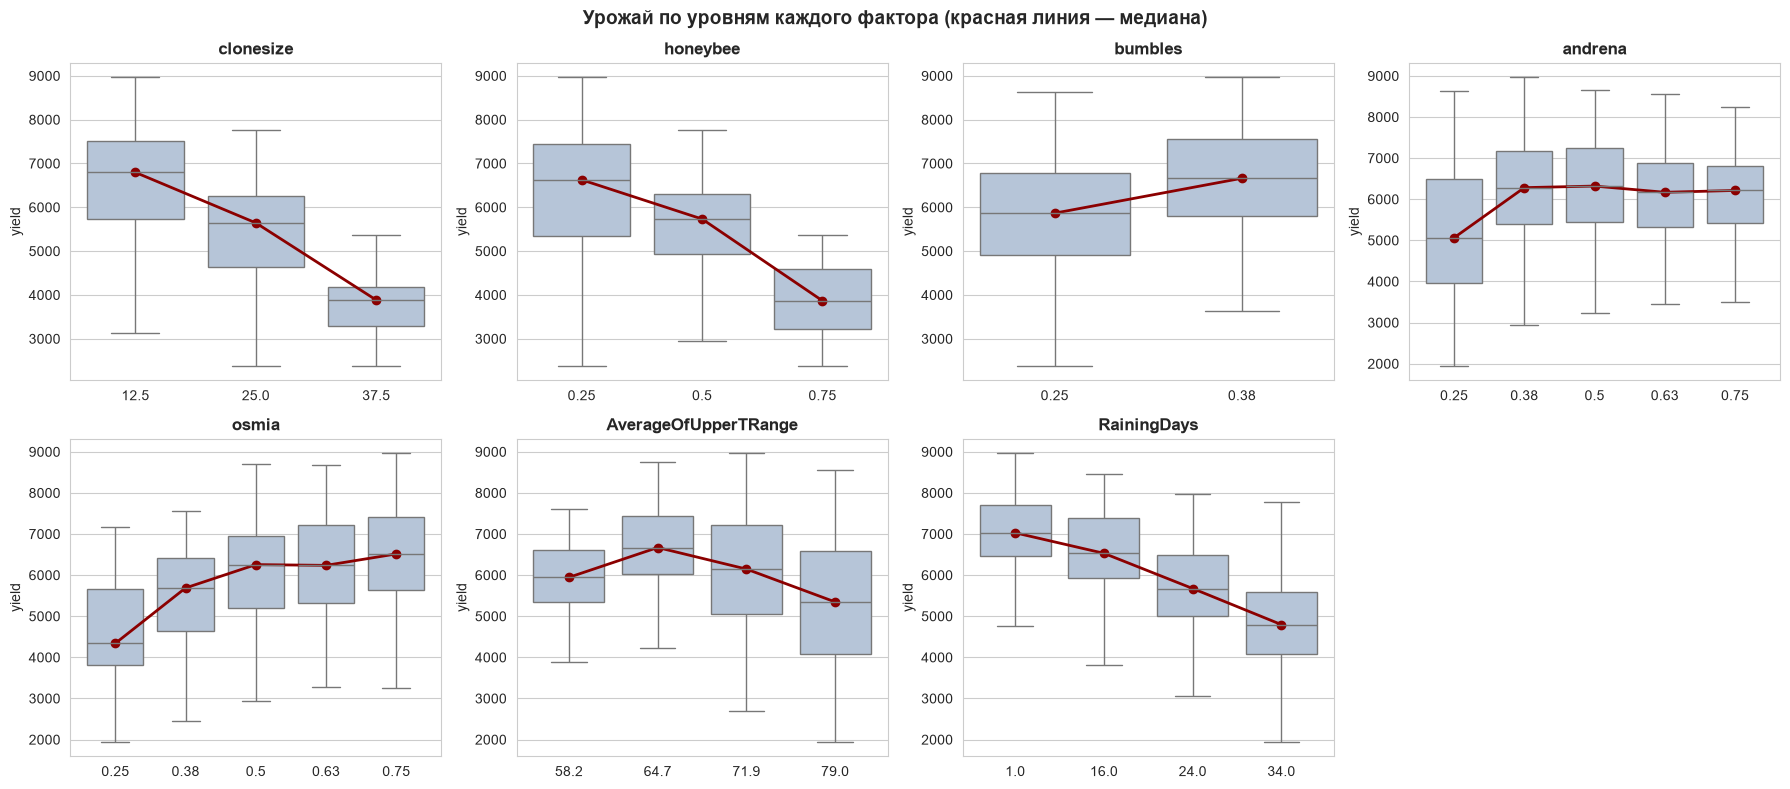

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=train, x=col, y=TARGET, color="lightsteelblue", ax=ax, showfliers=False)
    med = train.groupby(col)[TARGET].median().values
    ax.plot(range(len(med)), med, "o-", color="darkred", linewidth=2)
    ax.set_title(col, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
axes.flat[-1].axis("off")
fig.suptitle("Урожай по уровням каждого фактора (красная линия — медиана)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Инсайты
- **Температура — горб, а не прямая.** Лучший урожай при умеренной температуре (≈ 65 °F), и холоднее, и жарче — хуже. Линейная модель такую форму не увидит → **гипотеза Г1** (раздел 10).
- **Дожди — падение ускоряется** с ростом числа дождливых дней → **гипотеза Г2**.
- **Осмии и андрены — рост с насыщением**: основной прирост на первом шаге плотности, дальше почти плато → **гипотеза Г4**.
- **Клон**: чем крупнее клон, тем ниже урожай.
- **Медоносные пчёлы** выглядят почти бесполезными или даже вредными — это ловушка (раздел 6.5).

## **6.3 Корреляции φk (phik)**

Используем φk: для выявления нелинейных связей. Все наши признаки числовые, поэтому передаём их в `interval_cols`.

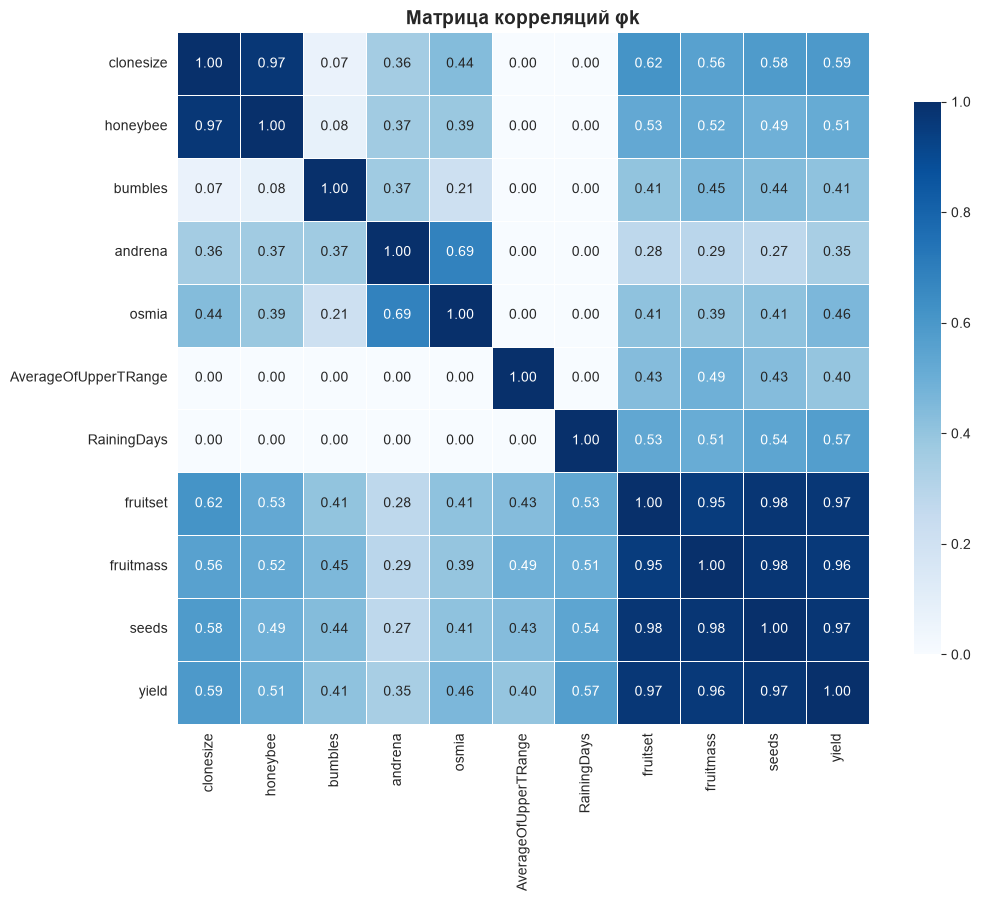

In [28]:
phik_cols = factors + outcomes + ['yield']
phik_matrix = train[phik_cols].phik_matrix(interval_cols=phik_cols)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            square=True, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Матрица корреляций φk', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

φk показывает **силу** связи, но не её **направление**. Направление смотрим по Пирсону.

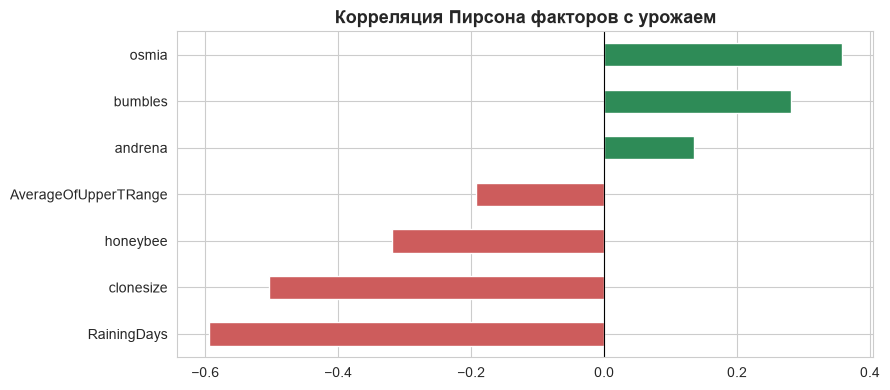

RainingDays            -0.594
clonesize              -0.505
honeybee               -0.319
AverageOfUpperTRange   -0.193
andrena                 0.136
bumbles                 0.281
osmia                   0.357
Name: yield, dtype: float64

In [29]:
pearson = train[factors + ['yield']].corr()['yield'].drop('yield').sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
pearson.plot(kind='barh', ax=ax, color=['indianred' if v < 0 else 'seagreen' for v in pearson])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Корреляция Пирсона факторов с урожаем', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

pearson.round(3)

### **Первые выводы:**
- Урожай сильнее всего связан с **дождями** и **размером клона** — обе связи отрицательные.
- **Осмии** и **шмели** — положительная связь.
- **Медоносная пчела** — отрицательная связь?! Неужели пчёлы вредят урожаю? Проверим.

## **6.4 Ранговые корреляции: Спирмен и Кендалл**

Пирсон измеряет только **линейную** связь и чувствителен к выбросам. Но у нас:
- факторы — это несколько уровней эксперимента, а не непрерывные величины;
- связь может быть **монотонной, но нелинейной** (у осмий урожай растёт быстро, потом выходит на плато).

Для таких случаев есть ранговые коэффициенты: они смотрят не на сами значения, а на их **порядок**.

| Коэффициент | Как считается | Что показывает |
|-------------|---------------|----------------|
| **Спирмен ρ** | Пирсон, посчитанный по рангам: $\rho = 1 - \dfrac{6\sum d_i^2}{n(n^2-1)}$, где $d_i$ — разница рангов (формула верна без совпадающих значений) | Насколько связь монотонна: «больше X → больше (или меньше) Y» |
| **Кендалл τ** | По парам наблюдений: $\tau = \dfrac{C - D}{\text{число пар}}$, где $C$ — согласованные пары (обе величины растут), $D$ — несогласованные | Насколько вероятнее, что две случайные строки упорядочены одинаково, чем противоположно |

**Почему здесь важен Кендалл τ-b.** Факторы принимают 3–5 значений, поэтому одинаковых рангов (связок) очень много. pandas и `scipy.stats.kendalltau` по умолчанию считают вариант **τ-b**, который поправляет на связки.

**Как читать значения.** Шкала та же, что у Пирсона: от −1 до +1, знак — направление связи. По модулю ориентир: < 0.3 — слабая, 0.3–0.7 — умеренная, > 0.7 — сильная.
Кендалл по модулю обычно **меньше** Спирмена (примерно в ⅔), поэтому их значения сравнивают каждый со своей шкалой, а не между собой.

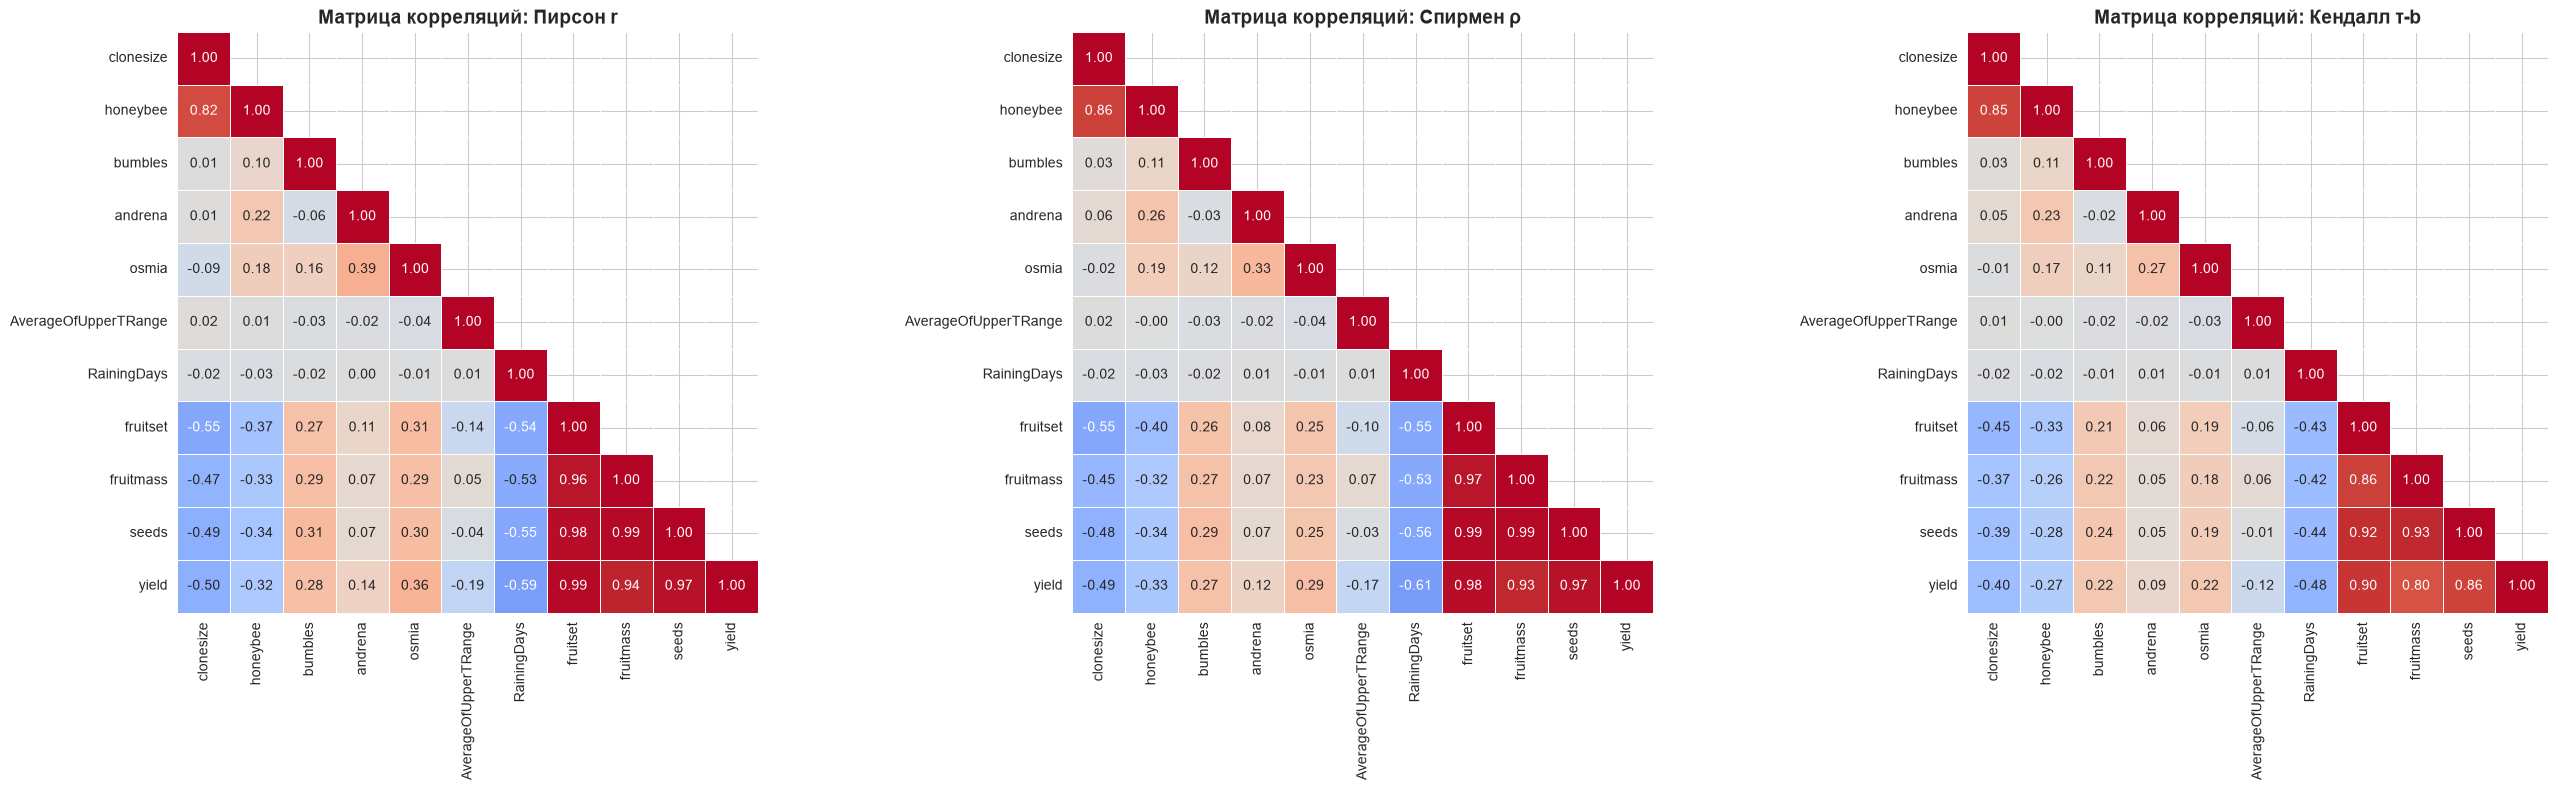

In [30]:
rank_cols = factors + outcomes + ['yield']
fig, axes = plt.subplots(1, 3, figsize=(27, 8))
for ax, method, title in zip(axes, ['pearson', 'spearman', 'kendall'], ['Пирсон r', 'Спирмен ρ', 'Кендалл τ-b']):
    corr = train[rank_cols].corr(method=method)
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0,
                mask=np.triu(np.ones_like(corr, dtype=bool), k=1), square=True, linewidths=0.5,
                ax=ax, cbar=False)
    ax.set_title(f'Матрица корреляций: {title}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### **Три коэффициента рядом: связь факторов с урожаем**

Для каждого фактора считаем Пирсона, Спирмена и Кендалла и проверяем значимость (p-value). Нулевая гипотеза — связи нет.

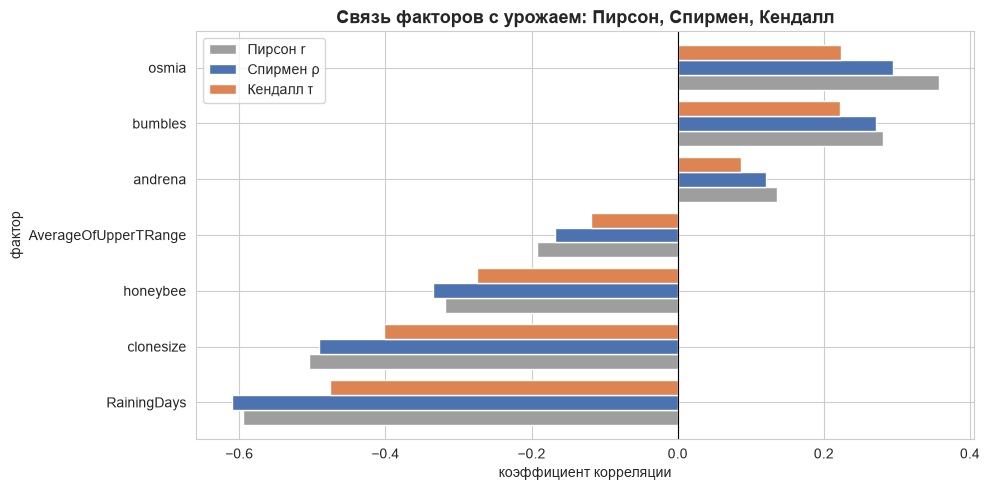

,Пирсон r,Спирмен ρ,p (Спирмен),Кендалл τ,p (Кендалл)
фактор,,,,,
RainingDays,-0.594,-0.611,2.6e-63,-0.476,1.4e-55
clonesize,-0.505,-0.491,4.5e-38,-0.402,1.1e-34
honeybee,-0.319,-0.335,2.2e-17,-0.275,8.9e-17
AverageOfUpperTRange,-0.193,-0.168,3.2e-05,-0.118,9.6e-05
andrena,+0.136,+0.120,3.0e-03,+0.087,3.7e-03
bumbles,+0.281,+0.271,1.1e-11,+0.221,2.5e-11
osmia,+0.357,+0.294,1.4e-13,+0.223,1.7e-13


In [31]:
rows = []
for col in factors:
    rho, p_rho = stats.spearmanr(train[col], train['yield'])
    tau, p_tau = stats.kendalltau(train[col], train['yield'])  # по умолчанию τ-b
    rows.append({'фактор': col,
                 'Пирсон r': train[col].corr(train['yield']),
                 'Спирмен ρ': rho, 'p (Спирмен)': p_rho,
                 'Кендалл τ': tau, 'p (Кендалл)': p_tau})

corr_compare = pd.DataFrame(rows).set_index('фактор').sort_values('Спирмен ρ')

fig, ax = plt.subplots(figsize=(10, 5))
corr_compare[['Пирсон r', 'Спирмен ρ', 'Кендалл τ']].plot(
    kind='barh', ax=ax, color=['#9E9E9E', '#4C72B0', '#DD8452'], width=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Связь факторов с урожаем: Пирсон, Спирмен, Кендалл', fontsize=13, fontweight='bold')
ax.set_xlabel('коэффициент корреляции')
plt.tight_layout()
plt.show()

corr_compare.style.format({'Пирсон r': '{:+.3f}', 'Спирмен ρ': '{:+.3f}', 'Кендалл τ': '{:+.3f}',
                           'p (Спирмен)': '{:.1e}', 'p (Кендалл)': '{:.1e}'})

In [32]:
# Та же проверка honeybee внутри клона 25 (см. раздел 6.5) — ранговыми методами
clone_25 = train[train['clonesize'] == 25]
rho_25, p_rho_25 = stats.spearmanr(clone_25['honeybee'], clone_25['yield'])
tau_25, p_tau_25 = stats.kendalltau(clone_25['honeybee'], clone_25['yield'])
print(f"Внутри клона 25:  Спирмен ρ = {rho_25:+.2f} (p = {p_rho_25:.1e}),  Кендалл τ = {tau_25:+.2f} (p = {p_tau_25:.1e})")

Внутри клона 25:  Спирмен ρ = +0.32 (p = 6.9e-08),  Кендалл τ = +0.26 (p = 1.4e-07)


### Что дали ранговые корреляции
- **Порядок факторов не изменился.** Сильнее всего с урожаем связаны дожди (ρ ≈ −0.61, τ ≈ −0.48) и размер клона (ρ ≈ −0.49, τ ≈ −0.40). Все связи значимы (p < 0.01).
- **Спирмен почти совпадает с Пирсоном** — связи в основном монотонные, сильной нелинейности, которую пропустил бы Пирсон, нет.
- **Осмии:** Спирмен (0.29) заметно ниже Пирсона (0.36). Это согласуется с эффектом насыщения: рост урожая после 0.5 почти прекращается, и Пирсон «вытягивает» связь за счёт крайних уровней.
- **Кендалл везде меньше по модулю** — это свойство коэффициента, а не более слабая связь.
- **Ранговые методы не спасают от смешения факторов.** У `honeybee` Спирмен по всей таблице тоже отрицательный (−0.34), а внутри клона 25 — положительный (≈ +0.32). Почему ни одной из этих цифр нельзя верить напрямую — в следующем разделе.

### Что ещё видно на матрицах
- **Температура** почти не коррелирует с урожаем ни по Пирсону, ни по Спирмену, хотя на графике 6.2 эффект большой. Обе меры ищут **монотонную** связь, а у температуры горб: рост и падение взаимно гасятся. Вывод: **низкая корреляция ≠ слабый признак** — нужен признак, описывающий оптимум.
- Между факторами корреляции в основном около нуля, **кроме двух пар**: `honeybee` — `clonesize` (0.82) и `andrena` — `osmia` (0.39). Первая пара — источник ловушки из раздела 6.5. Погода с пчёлами и клоном не связана совсем — её эффект можно оценивать отдельно.

## **6.5 Ловушка: смешение факторов**

В плане эксперимента плотность медоносных пчёл задавалась **вместе** с размером клона.

In [33]:
pd.crosstab(train['clonesize'], train['honeybee'])

honeybee,0.25,0.50,0.75
clonesize,,,
12.5,321,0,0
25.0,23,245,0
37.5,11,0,7


При клоне 12.5 пчёл всегда 0.25, при клоне 25 — почти всегда 0.5. Значит, «больше пчёл» в общей корреляции на самом деле означает «крупнее клон».
Сравним поля **с одинаковым** размером клона:

In [34]:
within = (train[train['clonesize'] == 25]
          .groupby('honeybee')['yield'].agg(['count', 'median']).round(0))
print("Клон 25 м²: урожай при разной плотности медоносных пчёл")
display(within)

corr_25 = train[train['clonesize'] == 25][['honeybee', 'yield']].corr().iloc[0, 1]
print(f"Корреляция honeybee и yield внутри клона 25: {corr_25:+.2f}")

# Одинаковы ли у этих полей остальные опылители?
c25 = train[train['clonesize'] == 25]
print("\nКлон 25: средняя плотность диких пчёл при разной плотности медоносных")
display(c25.groupby('honeybee')[['bumbles', 'andrena', 'osmia']].mean().round(2))
display(pd.crosstab(c25['honeybee'], c25['andrena']))

Клон 25 м²: урожай при разной плотности медоносных пчёл


,count,median
honeybee,,
0.25,23,4335.0
0.50,245,5732.0


Корреляция honeybee и yield внутри клона 25: +0.36

Клон 25: средняя плотность диких пчёл при разной плотности медоносных


,bumbles,andrena,osmia
honeybee,,,
0.25,0.25,0.25,0.31
0.50,0.29,0.53,0.62


andrena,0.25,0.38,0.50,0.63,0.75
honeybee,,,,,
0.25,23,0,0,0,0
0.50,0,74,78,53,40


### **Ключевой инсайт: смешение на двух уровнях**
**Уровень 1 — клон.** В общей таблице «больше медоносных пчёл» почти всегда значит «крупнее клон», а крупный клон даёт меньше ягод. Отсюда отрицательная общая корреляция.

**Уровень 2 — дикие пчёлы.** Внутри клона 25 урожай при пчёлах 0.50 на 32 % выше, чем при 0.25. Но все 23 поля с пчёлами 0.25 — это отдельный блок, где мало **всех** опылителей: андрены везде 0.25, осмии 0.25–0.38, шмели 0.25. Значит, и эта разница может быть эффектом диких пчёл, а не медоносных.

**Вывод:** по этим данным эффект медоносных пчёл **не оценить** — ни отрицательный, ни положительный. Их плотность ни разу не менялась при прочих равных.



**Вывод для модели:** признак `honeybee` оставляем (он известен до сезона), но **его коэффициент не интерпретируем** как пользу или вред ульев.

---
# **7. Сегментированный анализ**

Урожай по отдельным уровням факторов — в разделе 6.2. Здесь — сочетания условий и профиль высокого урожая.

## **7.1 Совместное влияние дождей и температуры**

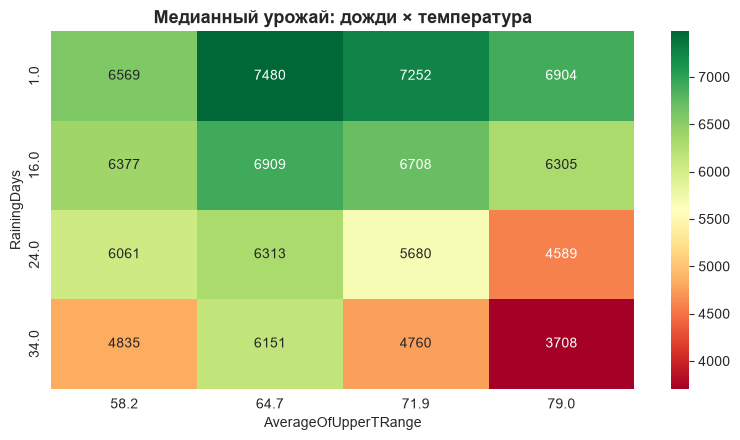

Потеря урожая от минимума к максимуму дождей при каждой температуре:
AverageOfUpperTRange
58.2    1734.0
64.7    1329.0
71.9    2492.0
79.0    3196.0


In [35]:
pivot = train.pivot_table(index="RainingDays", columns="AverageOfUpperTRange", values=TARGET, aggfunc="median")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn", ax=ax)
ax.set_title("Медианный урожай: дожди × температура", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
loss = (pivot.iloc[0] - pivot.iloc[-1]).round(0)
print("Потеря урожая от минимума к максимуму дождей при каждой температуре:")
print(loss.to_string())

**Дождь вредит сильнее в жару.** При умеренной температуре дожди отнимают меньше всего урожая, а в самую жаркую погоду — больше всего. Эффект одного фактора зависит от другого — это **взаимодействие** → **гипотеза Г3** (раздел 10).

## **7.2 Что даёт высокий урожай**

In [36]:
high_threshold = train['yield'].quantile(0.75)
train['is_high'] = (train['yield'] >= high_threshold).astype(int)

print(f"Порог высокого урожая: yield >= {high_threshold:.0f}")
print(train['is_high'].value_counts())
print(f"\nДоля высоких: {train['is_high'].mean() * 100:.1f}%")

Порог высокого урожая: yield >= 7024
is_high
0    455
1    152
Name: count, dtype: int64

Доля высоких: 25.0%


## **7.3 Высокий урожай и остальные поля**

In [37]:
compare_cols = factors + outcomes
high_comparison = train.groupby('is_high')[compare_cols].median().T
high_comparison.columns = ['Обычные поля', 'Высокий урожай']
high_comparison['Разница'] = high_comparison['Высокий урожай'] - high_comparison['Обычные поля']
high_comparison['Разница %'] = ((high_comparison['Высокий урожай'] / high_comparison['Обычные поля'] - 1) * 100).round(1)
high_comparison.round(3)

,Обычные поля,Высокий урожай,Разница,Разница %
clonesize,25.000,12.500,-12.500,-50.0
honeybee,0.500,0.250,-0.250,-50.0
bumbles,0.250,0.250,0.000,0.0
andrena,0.500,0.500,0.000,0.0
osmia,0.630,0.630,0.000,0.0
AverageOfUpperTRange,71.900,71.900,0.000,0.0
RainingDays,24.000,16.000,-8.000,-33.3
fruitset,0.483,0.596,0.113,23.4
fruitmass,0.434,0.495,0.062,14.2
seeds,34.864,41.385,6.521,18.7


### **Radar Chart «Профиль высокого урожая»**

Факторы в разных единицах, поэтому перед radar chart нормируем их в диапазон 0–1 (min-max).
Берём **средние**, а не медианы: у дискретных признаков медианы двух групп часто совпадают и скрывают разницу.

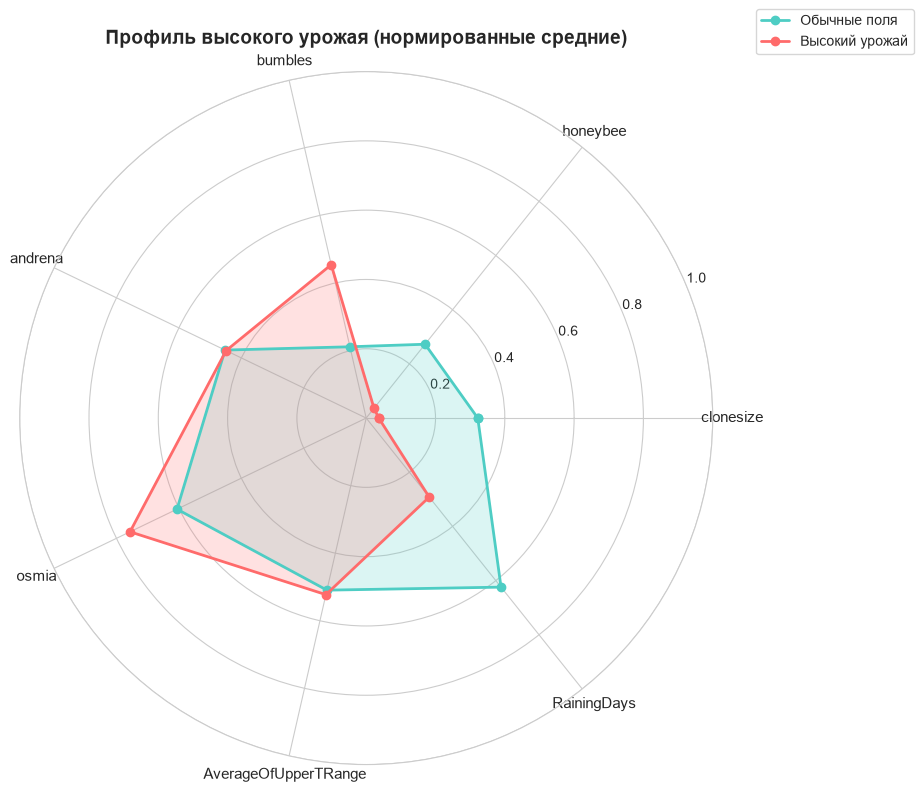

In [38]:
norm = train[factors].copy()
norm = (norm - norm.min()) / (norm.max() - norm.min())
norm['is_high'] = train['is_high']
profile_stats = norm.groupby('is_high')[factors].mean()

N = len(factors)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
for label, name, color in [(0, 'Обычные поля', '#4ECDC4'), (1, 'Высокий урожай', '#FF6B6B')]:
    values = profile_stats.loc[label].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=name, color=color)
    ax.fill(angles, values, alpha=0.2, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(factors, fontsize=11)
ax.set_ylim(0, 1)
ax.set_title('Профиль высокого урожая (нормированные средние)', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

## **7.4 Профили опылителей по размеру клона**

In [39]:
clone_bees = train.groupby('clonesize')[bees + ['yield']].mean().round(3)
clone_bees['строк'] = train['clonesize'].value_counts().sort_index()
clone_bees

,honeybee,bumbles,andrena,osmia,yield,строк
clonesize,,,,,,
12.5,0.250,0.283,0.461,0.569,6604.595,321
25.0,0.479,0.291,0.508,0.597,5467.556,268
37.5,0.444,0.250,0.250,0.250,3735.356,18


In [40]:
# Как плотность осмий связана с урожаем
osmia_yield = train.groupby('osmia')['yield'].agg(['count', 'median']).round(0)
osmia_yield

train = train.drop(columns='is_high')  # вспомогательный столбец раздела 7 больше не нужен

- Клон 37.5 — самый низкий урожай, но в этих строках и пчёл меньше всех (андрены и осмии по 0.25). Чистый эффект размера клона отсюда не отделить.
- Осмии: резкий рост урожая от 0.25 к 0.5, дальше прирост небольшой — эффект насыщения.
- Можно ли описать насыщение осмий отдельным признаком — гипотеза Г4 в разделе 10.

---
# **8. Выбор метрики качества**

### Основная метрика — **MAE** (средняя абсолютная ошибка)
Почему именно она для этой задачи:
1. **Понятна заказчику.** MAE измеряется в тех же единицах, что и урожай: «прогноз в среднем ошибается на N». Для планирования сбора, тары и рабочих это прямой ответ на вопрос «насколько можно доверять цифре».
2. **Цена ошибки примерно линейна.** Недобор и перебор на 200 единиц обходятся примерно одинаково (лишняя или недостающая тара и смена сборщиков), и ошибка на 400 — примерно вдвое дороже ошибки на 200. Это и есть MAE.
3. **Устойчива к отдельным сценариям.** Плохие сезоны (раздел 5.1) — редкие, но настоящие. MAE не даёт одному такому сценарию перекосить сравнение моделей.

### Вспомогательные метрики
| Метрика | Зачем нужна в этой задаче |
|---|---|
| **RMSE** | сильнее штрафует **крупные** промахи. Если RMSE заметно больше MAE — модель иногда сильно ошибается, обычно в неудачные сезоны (дожди + жара), где ошибка дороже всего |
| **R²** | доля объяснённого разброса, не зависит от единиц — удобно сравнивать с другими работами. Возьмем R² для подбора гиперпараметров в модели (`GridSearchCV(scoring="r2")`) |
| **MAPE** | ошибка в процентах. Корректна, потому что урожай всегда больше нуля (минимум ≈ 1 950, раздел 5.1). Показывает, что 300 при урожае 2 000 — это хуже, чем 300 при 8 000 |

**Согласованы ли метрики между собой.** При одних и тех же данных R² = 1 − MSE / дисперсия, то есть R² и RMSE ранжируют модели **одинаково**. Ниже проверим на всех вариантах из разделов 10–12, совпадает ли ранжирование по MAE и по R²: если да — выбор R² для подбора гиперпараметров в модели не противоречит основной метрике.

---
# **9. Схема валидации**

| Элемент | Решение | Почему |
|---|---|---|
| Отложенный тест | 20 % (152 строки), `random_state=1911` | финальная честная оценка, совпадает с моделью |
| Кросс-валидация на train | `KFold(n_splits=10, shuffle=True, random_state=1911)` | 10 частей по ~60 строк дают устойчивую оценку при 607 строках |
| Перемешивание | да | строки в файле упорядочены по плану эксперимента — без перемешивания части были бы непохожи друг на друга |
| Результат | **среднее ± стандартное отклонение по 10 фолдам** | одна цифра скрывает, насколько оценка зависит от разбиения |
| Предобработка | только внутри `Pipeline` | масштаб и прочие параметры считаются на обучающей части фолда (раздел 13) |

Все сравнения в тетрадке — на **одних и тех же 10 разбиениях**: разница между вариантами — это разница подходов, а не везение разбиения.

In [41]:
CV = KFold(n_splits=10, shuffle=True, random_state=SEED)
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error",
           "R2": "r2", "MAPE": "neg_mean_absolute_percentage_error"}

def cv_scores(model, Xd, yd=y):
    """Метрики по каждому из 10 фолдов (DataFrame: строка — фолд)."""
    res = cross_validate(model, Xd, yd, cv=CV, scoring=SCORING)
    out = pd.DataFrame({k: res[f"test_{k}"] for k in SCORING})
    for k in ["MAE", "RMSE", "MAPE"]:
        out[k] = -out[k]
    out["MAPE"] *= 100
    return out

def summary(folds):
    """Среднее ± разброс по фолдам."""
    return {f"{k}": f"{folds[k].mean():.{4 if k == 'R2' else 1}f} ± {folds[k].std():.{4 if k == 'R2' else 1}f}"
            for k in folds.columns} | {"_MAE": folds["MAE"].mean(), "_R2": folds["R2"].mean()}

base_folds = cv_scores(LinearRegression(), X)
base_folds.index = [f"фолд {i+1}" for i in range(10)]
display(base_folds.round(3).T)
print("Линейная регрессия на 7 факторах:",
      {k: v for k, v in summary(base_folds).items() if not k.startswith("_")})

,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,фолд 6,фолд 7,фолд 8,фолд 9,фолд 10
MAE,445.332,543.387,523.596,565.918,536.761,460.040,460.072,454.485,488.045,542.036
RMSE,557.535,647.662,654.172,656.761,643.800,532.559,570.372,598.399,585.893,654.505
R2,0.792,0.770,0.708,0.795,0.764,0.888,0.868,0.694,0.743,0.747
MAPE,7.985,9.437,9.787,10.500,9.223,8.156,8.750,7.523,8.910,10.155


Линейная регрессия на 7 факторах: {'MAE': '502.0 ± 45.0', 'RMSE': '610.2 ± 46.8', 'R2': '0.7770 ± 0.0623', 'MAPE': '9.0 ± 1.0'}


In [42]:
fold_37 = [int((X.iloc[v]["clonesize"] == 37.5).sum()) for _, v in CV.split(X)]
print(f"Клон 37.5 в train: {(X['clonesize'] == 37.5).sum()} строк; по фолдам валидации: {fold_37}")

Клон 37.5 в train: 18 строк; по фолдам валидации: [1, 1, 2, 3, 1, 3, 6, 0, 0, 1]


- Ошибка заметно меняется от фолда к фолду — поэтому **результат всегда приводим как среднее ± разброс**, и разницу между вариантами считаем существенной, только если она больше разброса.
- Редкий клон 37.5 распределён по фолдам неравномерно (в некоторых фолдах его нет). Возможно нужна стратификация по `clonesize`, но это задача регрессии.

---
# **10. Новые признаки и гипотезы**

Каждая гипотеза — из разделов 6 и 7. Проверка: добавляем признак к 7 факторам и смотрим ошибку **линейной регрессии** на той же кросс-валидации. Линейная модель видит только прямые зависимости, поэтому полезный признак, описывающий нелинейность, сразу снижает её ошибку.

| № | Гипотеза | Признак |
|---|---|---|
| Г1 | У температуры есть оптимум (6.2, 6.4) | `temp_sq` = температура² |
| Г2 | Вред от дождей нарастает (6.2) | `rain_sq` = дождливые дни² |
| Г3 | Дождь в жару вредит сильнее (7.1) | `rain_x_temp` = дни × температура |
| Г4 | Насыщение по осмиям и андренам (6.2) | `osmia_sq`, `andrena_sq` |
| Г5 | Важна общая плотность опылителей | `wild_bees` = шмели + андрены + осмии; `bees_per_clone` = все пчёлы / размер клона |

Оптимум температуры мы **не задаём числом** (например, |T − 65|): он найден на этих же данных, это была бы подгонка. Пара «T и T²» позволяет модели найти оптимум самой.

In [43]:
def add_features(d):
    d = d.copy()
    d["temp_sq"] = d["AverageOfUpperTRange"] ** 2
    d["rain_sq"] = d["RainingDays"] ** 2
    d["rain_x_temp"] = d["RainingDays"] * d["AverageOfUpperTRange"]
    d["osmia_sq"] = d["osmia"] ** 2
    d["andrena_sq"] = d["andrena"] ** 2
    d["wild_bees"] = d["bumbles"] + d["andrena"] + d["osmia"]
    d["bees_per_clone"] = (d["wild_bees"] + d["honeybee"]) / d["clonesize"]
    return d

XF = add_features(X)   # признаки строятся по строке — без статистик по выборке, утечки нет
CANDIDATES = {"temp_sq": "Г1", "rain_sq": "Г2", "rain_x_temp": "Г3", "osmia_sq": "Г4",
              "andrena_sq": "Г4", "wild_bees": "Г5", "bees_per_clone": "Г5"}
base = summary(base_folds)

rows = []
for feat, h in CANDIDATES.items():
    s = summary(cv_scores(LinearRegression(), XF[FEATURES + [feat]]))
    rows.append({"признак": feat, "гипотеза": h,
                 "Спирмен с yield": round(XF[feat].corr(y, method="spearman"), 3),
                 "MAE": s["MAE"], "ΔMAE": round(s["_MAE"] - base["_MAE"], 1), "R²": s["R2"]})
print(f"Без новых признаков: MAE {base['MAE']}, R² {base['R2']}")
pd.DataFrame(rows).set_index("признак")

Без новых признаков: MAE 502.0 ± 45.0, R² 0.7770 ± 0.0623


,гипотеза,Спирмен с yield,MAE,ΔMAE,R²
признак,,,,,
temp_sq,Г1,-0.168,389.2 ± 29.5,-112.8,0.8622 ± 0.0436
rain_sq,Г2,-0.611,468.4 ± 44.0,-33.5,0.7972 ± 0.0629
rain_x_temp,Г3,-0.632,473.8 ± 28.9,-28.2,0.8133 ± 0.0456
osmia_sq,Г4,0.294,502.0 ± 42.2,0.0,0.7774 ± 0.0635
andrena_sq,Г4,0.120,502.7 ± 46.2,0.8,0.7760 ± 0.0620
wild_bees,Г5,0.268,502.0 ± 45.0,-0.0,0.7770 ± 0.0623
bees_per_clone,Г5,0.573,495.1 ± 45.4,-6.9,0.7822 ± 0.0648


### Итог проверки по одному признаку

| Гипотеза | Итог |
|---|---|
| Г1. Оптимум температуры | **подтверждена**, самый сильный признак: ошибка падает больше, чем на разброс по фолдам |
| Г2. Вред дождей нарастает | подтверждена |
| Г3. Дождь в жару хуже | подтверждена |
| Г4. Насыщение осмий и андрен | **не подтверждена**: в такой форме нет: насыщение на графике есть, но это резкий скачок и плато, а квадрат описывает плавную параболу — ошибка не меняется |
| Г5. Сумма диких пчёл | **не подтверждена**: ΔMAE = 0: это точная сумма уже имеющихся признаков, линейная модель и так умеет их сложить |
| Г5. Пчёлы на м² клона | **не подтверждена**: почти ничего: корреляция с урожаем высокая, но взята из `clonesize`, который уже в модели. **Высокая корреляция ≠ полезный признак** |

## 10.1 Признаки вместе и при использовании `PolynomialFeatures` в модели

,признаков,MAE,RMSE,R2,MAPE
7 факторов,7,502.0 ± 45.0,610.2 ± 46.8,0.7770 ± 0.0623,9.0 ± 1.0
7 + temp_sq,8,389.2 ± 29.5,479.0 ± 33.4,0.8622 ± 0.0436,7.0 ± 0.4
7 + temp_sq + rain_sq,9,342.9 ± 34.7,438.1 ± 37.9,0.8845 ± 0.0390,6.2 ± 0.6
7 + 3 новых (Г1–Г3),10,285.0 ± 29.1,367.2 ± 29.6,0.9196 ± 0.0239,5.2 ± 0.6
PolynomialFeatures(2),35,266.0 ± 39.3,342.4 ± 43.1,0.9291 ± 0.0249,4.8 ± 0.8
PolynomialFeatures(3),119,230.7 ± 16.2,287.3 ± 18.4,0.9513 ± 0.0110,4.1 ± 0.4


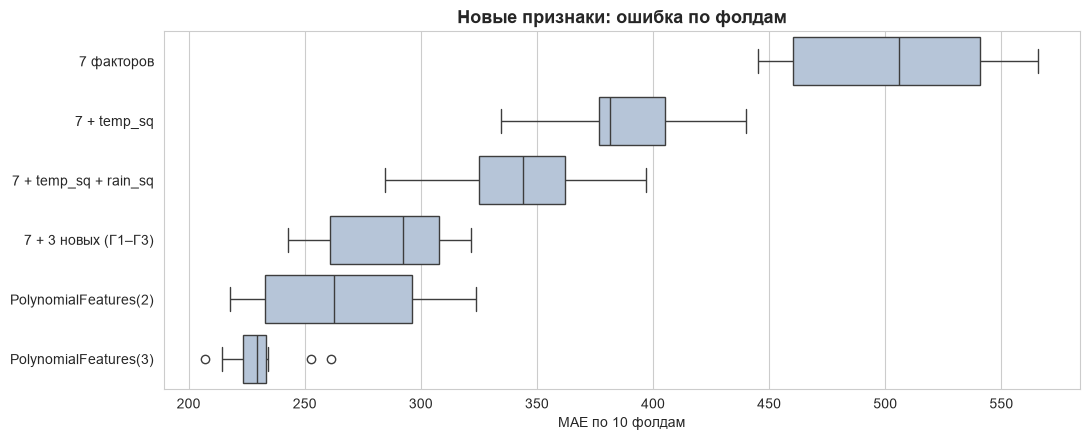

In [44]:
NEW = ["temp_sq", "rain_sq", "rain_x_temp"]
def poly_ridge(degree):
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False), StandardScaler(), Ridge(alpha=0.5))

variants = {
    "7 факторов": (LinearRegression(), XF[FEATURES], 7),
    "7 + temp_sq": (LinearRegression(), XF[FEATURES + NEW[:1]], 8),
    "7 + temp_sq + rain_sq": (LinearRegression(), XF[FEATURES + NEW[:2]], 9),
    "7 + 3 новых (Г1–Г3)": (LinearRegression(), XF[FEATURES + NEW], 10),
    "PolynomialFeatures(2)": (poly_ridge(2), X, 35),
    "PolynomialFeatures(3)": (poly_ridge(3), X, 119),
}
fe_folds = {name: cv_scores(m, Xd) for name, (m, Xd, _) in variants.items()}
fe_table = pd.DataFrame({name: {"признаков": n, **summary(fe_folds[name])} for name, (_, _, n) in variants.items()}).T
display(fe_table.drop(columns=["_MAE", "_R2"]))

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=pd.DataFrame({k: v["MAE"] for k, v in fe_folds.items()}), orient="h", color="lightsteelblue", ax=ax)
ax.set_xlabel("MAE по 10 фолдам")
ax.set_title("Новые признаки: ошибка по фолдам", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Что это значит для модели
- Три подтверждённых признака (Г1–Г3) снижают ошибку линейной модели **почти вдвое**, и ящики на графике не пересекаются — эффект намного больше разброса по фолдам.
- `PolynomialFeatures(3)` использование в модели — **автоматическое обобщение тех же гипотез**: квадраты и произведения всех пар и троек факторов. Он содержит `temp_sq`, `rain_sq`, `rain_x_temp` и ещё более сотни членов, поэтому немного точнее, но коэффициенты уже не прочитать.
- Наши гипотезы **обосновывают** выбор полиномиальных признаков для модели: нелинейность и взаимодействия в данных есть, и именно они дают основной выигрыш. А 10 признаков (7 + 3) — интерпретируемая альтернатива, почти не уступающая по точности второй степени.

---
# **11. Стратегия предобработки**

## 11.1 Пропуски

In [45]:
print("Пропусков в train по столбцам:", int(train.isna().sum().sum()))
print("Бесконечных значений:", int(np.isinf(train.select_dtypes("number")).sum().sum()))

Пропусков в train по столбцам: 0
Бесконечных значений: 0


Пропусков нет — симуляция выдаёт полную таблицу (раздел 4.1). **Заполнение не нужно**, и сравнивать способы заполнения не на чем. Если модель будут применять к полевым данным, в начало конвейера стоит поставить `SimpleImputer(strategy="median")` (медиана — потому что плотности пчёл скошены) — внутри `Pipeline`, чтобы медиана считалась только по обучающей части.

## 11.2 Кодирование
Все признаки числовые, но у каждого всего 2–5 уровней. Значит, их можно подать как числа, а можно как категории. Сравниваем три варианта на той же схеме:
- **числа** — сохраняют порядок уровней, признаков мало;
- **one-hot** — каждый уровень становится отдельным признаком, модель получает любую форму зависимости;
- **target encoding** — уровень заменяется средним урожаем на этом уровне. Это кодирование использует цель, поэтому его можно делать **только внутри фолда** (в `TargetEncoder` это встроено).

In [46]:
n_levels = sum(X[c].nunique() for c in FEATURES)
enc_variants = {
    "числа": (LinearRegression(), X, 7),
    "one-hot": (make_pipeline(OneHotEncoder(handle_unknown="ignore"), LinearRegression()), X, n_levels),
    "target encoding": (make_pipeline(TargetEncoder(target_type="continuous", random_state=SEED), LinearRegression()),
                        X.astype(str), 7),
    "числа + 3 новых": (LinearRegression(), XF[FEATURES + NEW], 10),
    "числа → PolynomialFeatures(3)": (poly_ridge(3), X, 119),
}
enc_table = pd.DataFrame({name: {"признаков": n, **summary(cv_scores(m, Xd))}
                          for name, (m, Xd, n) in enc_variants.items()}).T
enc_table.drop(columns=["_MAE", "_R2"])

,признаков,MAE,RMSE,R2,MAPE
числа,7,502.0 ± 45.0,610.2 ± 46.8,0.7770 ± 0.0623,9.0 ± 1.0
one-hot,26,319.3 ± 25.1,394.7 ± 29.4,0.9065 ± 0.0285,5.6 ± 0.6
target encoding,7,361.1 ± 26.2,452.2 ± 36.6,0.8793 ± 0.0322,6.6 ± 0.8
числа + 3 новых,10,285.0 ± 29.1,367.2 ± 29.6,0.9196 ± 0.0239,5.2 ± 0.6
числа → PolynomialFeatures(3),119,230.7 ± 16.2,287.3 ± 18.4,0.9513 ± 0.0110,4.1 ± 0.4


### Решение по кодированию — **числа**
- One-hot и target encoding заметно лучше «голых» чисел: это ещё одно подтверждение, что зависимости нелинейные.
- Но числа + полиномиальные (или наши 3) признаки **точнее обоих**: они описывают нелинейность и при этом сохраняют порядок уровней.
- One-hot не умеет работать с уровнем, которого не было в обучении (например, температура 75 °F), а числовые признаки дают осмысленный прогноз между уровнями.

## 11.3 Масштабирование — зачем оно здесь вообще
Признаки в очень разных единицах: плотность пчёл 0.25–0.75, клон 12.5–37.5, температура 58–79, а после `PolynomialFeatures(3)` появляются члены вроде T³ ≈ 500 000.
- **Ridge** штрафует сумму квадратов коэффициентов → без масштабирования штраф зависит от единиц измерения, а не от полезности признака.
- **PolynomialFeatures** без центрирования даёт сильно коррелирующие члены (T, T², T³ почти пропорциональны на отрезке 58–79) → коэффициенты неустойчивы.
- Поэтому в модели масштабирование необходимо применить **дважды**: до полиномов (центрировать факторы) и после (выровнять масштаб новых членов). Какой способ лучше — в разделе 12.

---
# **12. Сравнение способов масштабирования**

**Конвейер:** `scaler → PolynomialFeatures(3) → scaler → Ridge`. Меняем только способ масштабирования.
**Схема:** те же 10 фолдов на train, метрики — среднее ± разброс.

| Способ | Что делает | Центрирует? |
|---|---|---|
| без масштабирования | — | нет |
| `StandardScaler` | (x − среднее) / стандартное отклонение | да |
| `RobustScaler` | (x − медиана) / межквартильный размах | да |
| `MinMaxScaler` | в отрезок [0, 1] | нет (минимум → 0) |
| `MaxAbsScaler` | деление на максимум модуля | нет |
| `QuantileTransformer` | ранги → равномерное распределение | нелинейно меняет расстояния |
| `Normalizer` | каждую **строку** делит на её длину | масштабирует объекты, а не признаки |

**Две постановки:**
1. `alpha = 0.5` — одна сила штрафа для всех способов;
2. `alpha` подобрана для каждого способа заново (`RidgeCV` внутри обучающей части каждого фолда) — честное сравнение «лучшее против лучшего».

In [47]:
SCALERS = {"без масштабирования": None, "StandardScaler": StandardScaler(), "RobustScaler": RobustScaler(),
           "MinMaxScaler": MinMaxScaler(), "MaxAbsScaler": MaxAbsScaler(),
           "QuantileTransformer": QuantileTransformer(n_quantiles=100), "Normalizer": Normalizer()}
ALPHAS = np.logspace(-4, 3, 29)

def model_pipe(scaler, regressor):
    """Конвейер модели: scaler → PolynomialFeatures(3) → scaler → регрессия."""
    pre = [clone(scaler)] if scaler is not None else []
    post = [clone(scaler)] if scaler is not None else []
    return make_pipeline(*pre, PolynomialFeatures(3, include_bias=False), *post, regressor)

rows, scale_folds, coefs = [], {}, {}
for name, sc in SCALERS.items():
    folds = cv_scores(model_pipe(sc, Ridge(alpha=0.5)), X)
    scale_folds[name] = folds
    fitted = model_pipe(sc, Ridge(alpha=0.5)).fit(X, y)          # на всём train — чтобы посмотреть коэффициенты
    c = fitted[-1].coef_
    coefs[name] = c
    tuned_folds = cv_scores(model_pipe(sc, RidgeCV(alphas=ALPHAS)), X)
    tuned_alpha = model_pipe(sc, RidgeCV(alphas=ALPHAS)).fit(X, y)[-1].alpha_
    s, st = summary(folds), summary(tuned_folds)
    rows.append({"масштабирование": name,
                 "MAE (α=0.5)": s["MAE"], "R² (α=0.5)": s["R2"],
                 "коэффициентов": len(c),
                 "существенных (>1% max)": int((np.abs(c) > 0.01 * np.abs(c).max()).sum()),
                 "max |коэф.|": round(np.abs(c).max()),
                 "медиана |коэф.|": round(np.median(np.abs(c)), 1),
                 "подобранная α": round(tuned_alpha, 4),
                 "MAE (α подобрана)": st["MAE"], "R² (α подобрана)": st["R2"],
                 "_MAE": s["_MAE"]})
scaling_table = pd.DataFrame(rows).set_index("масштабирование").sort_values("_MAE")
scaling_table.drop(columns="_MAE")

,MAE (α=0.5),R² (α=0.5),коэффициентов,существенных (>1% max),max |коэф.|,медиана |коэф.|,подобранная α,MAE (α подобрана),R² (α подобрана)
масштабирование,,,,,,,,,
RobustScaler,228.8 ± 16.9,0.9526 ± 0.0125,119,94,1788,49.7,0.3162,229.1 ± 17.3,0.9523 ± 0.0124
StandardScaler,230.7 ± 16.2,0.9513 ± 0.0110,119,108,892,39.0,0.5623,229.9 ± 17.3,0.9517 ± 0.0116
без масштабирования,246.7 ± 27.2,0.9437 ± 0.0150,119,42,2108,8.9,0.0056,228.4 ± 16.0,0.9522 ± 0.0098
MinMaxScaler,264.6 ± 30.3,0.9337 ± 0.0210,119,99,1974,158.6,0.0100,227.5 ± 18.1,0.9525 ± 0.0125
QuantileTransformer,305.1 ± 37.2,0.9068 ± 0.0293,119,102,2333,133.6,0.0178,300.2 ± 41.9,0.9123 ± 0.0301
MaxAbsScaler,382.4 ± 41.5,0.8661 ± 0.0446,119,112,2737,212.0,0.0001,253.5 ± 27.5,0.9404 ± 0.0166
Normalizer,790.6 ± 76.2,0.4415 ± 0.0756,119,54,2828,12.5,0.0001,519.6 ± 60.6,0.7553 ± 0.0649


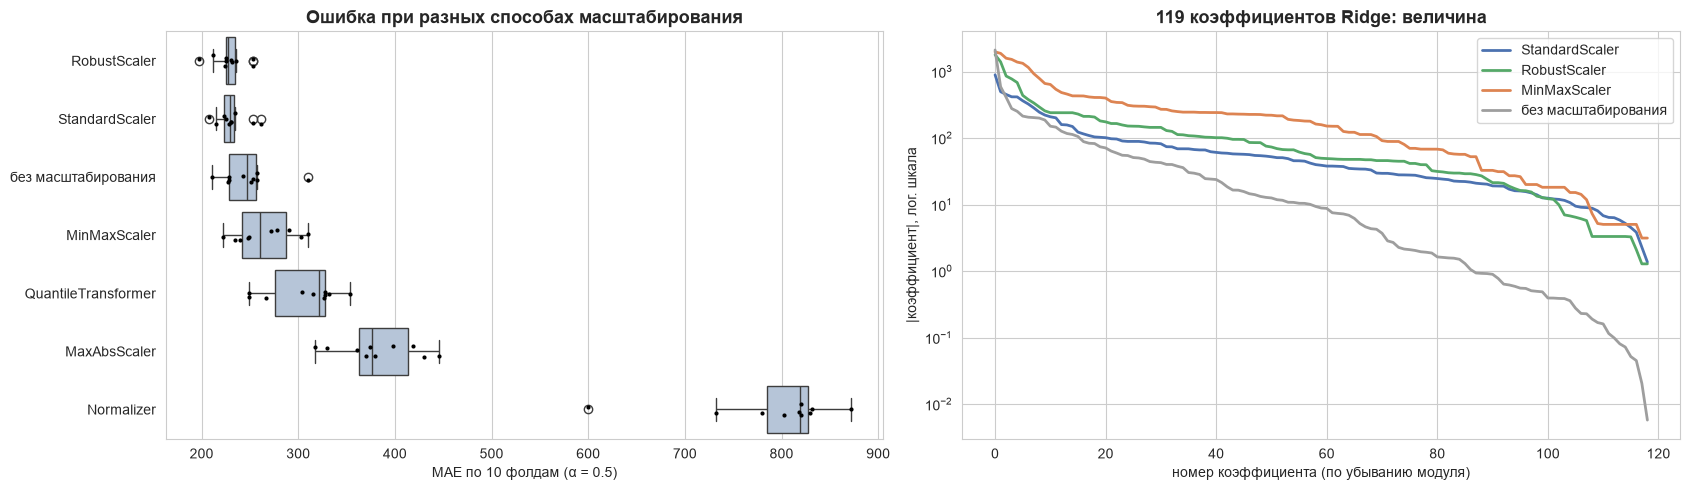

In [48]:
order = scaling_table.index
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
mae_df = pd.DataFrame({k: scale_folds[k]["MAE"] for k in order})
sns.boxplot(data=mae_df, orient="h", color="lightsteelblue", ax=axes[0])
sns.stripplot(data=mae_df, orient="h", color="black", size=3, ax=axes[0])
axes[0].set_xlabel("MAE по 10 фолдам (α = 0.5)")
axes[0].set_title("Ошибка при разных способах масштабирования", fontsize=13, fontweight="bold")

for name, color in zip(["StandardScaler", "RobustScaler", "MinMaxScaler", "без масштабирования"],
                       ["#4C72B0", "#55A868", "#DD8452", "#9E9E9E"]):
    axes[1].plot(np.sort(np.abs(coefs[name]))[::-1], label=name, color=color, linewidth=2)
axes[1].set_yscale("log")
axes[1].set_xlabel("номер коэффициента (по убыванию модуля)")
axes[1].set_ylabel("|коэффициент|, лог. шкала")
axes[1].set_title("119 коэффициентов Ridge: величина", fontsize=13, fontweight="bold")
axes[1].legend()
plt.tight_layout()
plt.show()

### Число ненулевых коэффициентов: Lasso

Ridge никогда не обнуляет коэффициенты — у него при любом масштабировании их 119. Чтобы увидеть, как масштабирование влияет на **число** используемых признаков, возьмём Lasso (L1-штраф) с одинаковой силой штрафа в том же конвейере.

In [49]:
lasso_rows = []
for name in ["без масштабирования", "StandardScaler", "RobustScaler", "MinMaxScaler", "MaxAbsScaler"]:
    pipe = model_pipe(SCALERS[name], Lasso(alpha=1.0, max_iter=50_000))
    s = summary(cv_scores(pipe, X))
    c = pipe.fit(X, y)[-1].coef_
    lasso_rows.append({"масштабирование": name, "MAE": s["MAE"], "R²": s["R2"],
                       "ненулевых из 119": int((np.abs(c) > 1e-8).sum())})
pd.DataFrame(lasso_rows).set_index("масштабирование")

,MAE,R²,ненулевых из 119
масштабирование,,,
без масштабирования,250.3 ± 26.5,0.9418 ± 0.0175,57
StandardScaler,226.3 ± 17.3,0.9537 ± 0.0124,77
RobustScaler,222.8 ± 17.0,0.9550 ± 0.0134,66
MinMaxScaler,264.5 ± 29.8,0.9345 ± 0.0206,42
MaxAbsScaler,306.1 ± 40.5,0.9082 ± 0.0322,21


In [50]:
# Совпадает ли ранжирование вариантов по основной метрике (MAE) и по R² (которым подбирает модель)?
all_variants = pd.concat([
    pd.DataFrame({"MAE": [v["MAE"].mean() for v in fe_folds.values()], "R2": [v["R2"].mean() for v in fe_folds.values()]}),
    pd.DataFrame({"MAE": [v["MAE"].mean() for v in scale_folds.values()], "R2": [v["R2"].mean() for v in scale_folds.values()]}),
])
rho = all_variants["MAE"].corr(-all_variants["R2"], method="spearman")
print(f"Вариантов: {len(all_variants)}. Ранговая корреляция «чем меньше MAE, тем больше R²»: {rho:.3f}")

Вариантов: 13. Ранговая корреляция «чем меньше MAE, тем больше R²»: 1.000


### Выводы по масштабированию

**Метрика при α = 0.5 (как в модели).**
- Лучше всех — **способы с центрированием**: `RobustScaler` (228.8 ± 16.9) и `StandardScaler` (230.7 ± 16.2). Их разница намного меньше разброса по фолдам — статистически они равноценны.
- `MinMaxScaler` и `MaxAbsScaler` не центрируют данные: члены T, T², T³ после них сильно коррелируют, и тот же штраф сильнее портит модель.

**Метрика при подобранной α.**
- `RobustScaler`, `StandardScaler`, `MinMaxScaler` и даже вариант без масштабирования сходятся к MAE ≈ 228–230 — разница в пределах разброса. Подобранная `α` у них разная (от 0.006 до 0.56): масштабирование меняет, **какая сила штрафа нужна**. Значит, при одинаковой `α` выбор масштабирования важен, а при подборе `α` под каждый способ — почти нет.
- `MaxAbsScaler` не догоняет лидеров даже с подобранной `α`.
- `QuantileTransformer` нелинейно «растягивает» шкалу и искажает форму зависимостей (параболу температуры), которую потом должны описать полиномы.
- `Normalizer` масштабирует **строки, а не столбцы**: делит все признаки объекта на одно число, смешивая температуру с плотностью пчёл. Для этой задачи он неприменим — худший результат.

**Коэффициенты.**
- Число у Ridge всегда 119, но **величина** сильно зависит от масштабирования (график справа). Без масштабирования коэффициенты отличаются в сотни тысяч раз: члены с огромными единицами (T³ ≈ 500 000) получают крошечные коэффициенты — только 42 из 119 больше 1 % от максимума. Это следствие единиц измерения, а не важности, — такие коэффициенты нельзя сравнивать.
- После `StandardScaler` коэффициенты самые ровные: наименьший максимум (892) и 108 из 119 существенных. У `RobustScaler` максимум больше (1 788): у `bumbles` межквартильный размах мал (0.13), деление на него растягивает шкалу.
- Lasso показывает, что от масштабирования зависит и **число** коэффициентов: от 21 (`MaxAbsScaler`) до 77 (`StandardScaler`) ненулевых из 119 при одной и той же силе штрафа. Без масштабирования штраф определяется единицами измерения — обнуляются признаки с «неудобными» единицами, а не бесполезные.

**Согласованность метрик:** ранжирование 13 вариантов по MAE и по R² **совпадает полностью** (ранговая корреляция 1.0) — подбор гиперпараметров по R² в модели не противоречит основной метрике MAE.

### Решение
**`RobustScaler` до и после `PolynomialFeatures`** — рекомендации для модели:
- лучшая средняя ошибка на схеме валидации при `α` модели, на уровне `StandardScaler` в пределах разброса; с Lasso — тоже лучший результат;
- центрирует данные — снижает корреляцию полиномиальных членов;
- медиана и межквартильный размах не зависят от редких крайних сценариев, а `StandardScaler` такой устойчивости не даёт.

`StandardScaler` — равноценная альтернатива. Если модель заменят на деревья (лес, бустинг), масштабирование не нужно: разбиения по порогам от масштаба не зависят.

---
# **13. Проверка на утечки данных**

Утечка — когда при обучении модель получает информацию, которой не будет в момент прогноза. Оценка качества тогда завышена. Проверяем все возможные источники.

## 13.1 Утечка цели: признаки, известные только после сбора

In [51]:
print("Корреляция с урожаем:", train[LEAKY + [TARGET]].corr()[TARGET].drop(TARGET).round(3).to_dict())
leak = summary(cv_scores(LinearRegression(), train[FEATURES + LEAKY]))
print(f"Линейная регрессия С ними:  MAE {leak['MAE']}, R² {leak['R2']}")
print(f"Линейная регрессия БЕЗ них: MAE {base['MAE']}, R² {base['R2']}")
assert not set(LEAKY) & set(FEATURES), "в признаках есть утечка цели"
print("fruitset, fruitmass, seeds в признаках отсутствуют")

Корреляция с урожаем: {'fruitset': 0.986, 'fruitmass': 0.94, 'seeds': 0.971}
Линейная регрессия С ними:  MAE 95.7 ± 10.9, R² 0.9910 ± 0.0025
Линейная регрессия БЕЗ них: MAE 502.0 ± 45.0, R² 0.7770 ± 0.0623
fruitset, fruitmass, seeds в признаках отсутствуют


С ними даже простая линейная регрессия получает R² ≈ 0.99 — «слишком хорошо». Это доля завязавшихся плодов, масса ягоды и число семян: их измеряют **на собранном урожае**. До сезона их нет, поэтому в признаки они не входят.

## 13.2 Предобработка учится только на обучающей части фолда
Все шаги (масштабирование, полиномы, кодирование, подбор `α`) стоят внутри `Pipeline`, поэтому `cross_validate` обучает их заново в каждом фолде. Проверим это прямо: вставим в конвейер «шпиона», который запоминает, на скольких строках его обучали.

In [52]:
class FitSpy(BaseEstimator, TransformerMixin):
    """Ничего не меняет, только запоминает, на каких строках вызывали fit."""
    log = []
    def fit(self, Xs, ys=None):
        FitSpy.log.append(len(Xs))
        return self
    def transform(self, Xs):
        return Xs

FitSpy.log = []
spy_pipe = make_pipeline(FitSpy(), RobustScaler(), PolynomialFeatures(3, include_bias=False), RobustScaler(), Ridge(alpha=0.5))
cross_validate(spy_pipe, X, y, cv=CV)
print(f"Строк в train: {len(X)}, в данных до разбиения: {len(data)}")
print(f"Предобработку обучали на: {FitSpy.log}")
assert max(FitSpy.log) < len(X), "предобработка видела валидационную часть фолда"
print("В каждом фолде масштаб считается только по 9/10 train — валидация и тест в обучении не участвуют")

Строк в train: 607, в данных до разбиения: 759
Предобработку обучали на: [546, 546, 546, 546, 546, 546, 546, 547, 547, 547]
В каждом фолде масштаб считается только по 9/10 train — валидация и тест в обучении не участвуют


**Насколько это важно здесь.** Сравним правильный вариант с «утекающим», где масштаб или кодирование посчитаны заранее по всему train:

In [53]:
def leaky_frame(transformer, Xd):
    return pd.DataFrame(transformer.fit_transform(Xd), columns=Xd.columns, index=Xd.index)

te_leaky = X.copy()
for c in FEATURES:                                    # среднее урожая по уровню — по ВСЕМУ train, включая валидацию
    te_leaky[c] = train.groupby(c)[TARGET].transform("mean")

leak_rows = {
    "RobustScaler: внутри Pipeline": cv_scores(model_pipe(RobustScaler(), Ridge(alpha=0.5)), X),
    "RobustScaler: по всему train заранее": cv_scores(
        make_pipeline(PolynomialFeatures(3, include_bias=False), RobustScaler(), Ridge(alpha=0.5)),
        leaky_frame(RobustScaler(), X)),
    "Target encoding: внутри Pipeline": cv_scores(
        make_pipeline(TargetEncoder(target_type="continuous", random_state=SEED), LinearRegression()), X.astype(str)),
    "Target encoding: по всему train заранее": cv_scores(LinearRegression(), te_leaky),
}
pd.DataFrame({k: summary(v) for k, v in leak_rows.items()}).T.drop(columns=["_MAE", "_R2"])

,MAE,RMSE,R2,MAPE
RobustScaler: внутри Pipeline,228.8 ± 16.9,282.1 ± 19.0,0.9526 ± 0.0125,4.1 ± 0.3
RobustScaler: по всему train заранее,228.5 ± 17.6,282.2 ± 20.4,0.9525 ± 0.0125,4.1 ± 0.4
Target encoding: внутри Pipeline,361.1 ± 26.2,452.2 ± 36.6,0.8793 ± 0.0322,6.6 ± 0.8
Target encoding: по всему train заранее,355.1 ± 23.9,444.5 ± 34.3,0.8838 ± 0.0284,6.5 ± 0.8


На этих данных разница невелика: масштаб «заранее» не меняет ничего, а target encoding «заранее» уже даёт чуть заниженную (слишком оптимистичную) ошибку. Почему так мало: у каждого признака всего 2–5 уровней, и все они есть в каждом фолде, поэтому параметры масштаба и средние по уровням почти не меняются от фолда к фолду. **На реальных полевых данных** (выбросы, редкие значения) утекающий вариант дал бы заметно завышенную оценку — поэтому правило «всё в `Pipeline`» соблюдаем всегда, а не только когда это видно в метриках.

## 13.3 Остальные источники

In [54]:
checks = {
    "Тест отложен до любого анализа, индексы не пересекаются":
        set(train.index).isdisjoint(test.index),
    "Нет одинаковых сценариев (одинаковых признаков) в train и test":
        train[FEATURES].merge(test[FEATURES], how="inner").empty,
    "Нет дублей сценариев внутри train":
        not X.duplicated().any(),
    "Row# (номер строки, порядок плана эксперимента) удалён":
        "Row#" not in X.columns,
    "Отбор строк — по признаку clonesize, цель не использовалась":
        set(X["clonesize"].unique()) <= set(GRID_CLONES),
    "Новые признаки считаются по одной строке, без статистик по выборке":
        True,
    "Гиперпараметры (α) подбираются внутри обучающей части фолда (RidgeCV в Pipeline)":
        True,
}
for text, ok in checks.items():
    print(("да  — " if ok else "НЕТ — ") + text)
assert all(checks.values())

да  — Тест отложен до любого анализа, индексы не пересекаются
да  — Нет одинаковых сценариев (одинаковых признаков) в train и test
да  — Нет дублей сценариев внутри train
да  — Row# (номер строки, порядок плана эксперимента) удалён
да  — Отбор строк — по признаку clonesize, цель не использовалась
да  — Новые признаки считаются по одной строке, без статистик по выборке
да  — Гиперпараметры (α) подбираются внутри обучающей части фолда (RidgeCV в Pipeline)


**Итог по утечкам:** признаки «после сбора» исключены, тест отложен до анализа и нигде не используется, вся предобработка и подбор параметров — внутри `Pipeline` и обучаются только на обучающей части фолда, пересечений и дублей сценариев между частями нет.

**Оговорка, которую нельзя устранить:** данные — симуляция с сеткой значений. Каждая комбинация уровней в тесте собрана из тех же уровней, что в обучении. Это не утечка, но оценка качества относится только к условиям **внутри этой сетки**: для новых значений (например, 15 дождливых дней при 75 °F) точность может быть ниже.

---

# **14. Итоги**

## 14.1 Что показал анализ данных

### 1. Это данные симуляции, а не наблюдения.
Признаки — уровни плана эксперимента. `value_counts()` показывает структуру эксперимента, а не реальность.

### 2. Качество данных
| Проверка | Результат |
|----------|-----------|
| Пропуски | нет |
| Дубликаты | нет |
| Аномалии | 18 строк особого блока (Row# 759–776) — отделены (раздел 4.4) |
| Отложенный тест | 152 строки, `random_state=1911` — те же, что в модели (раздел 4.5) |
| Избыточность | 6 температур ≈ 1 фактор, 2 столбца дождей ≈ 1 фактор |
| Утечка цели | `fruitset`, `fruitmass`, `seeds` — результаты, а не причины |

### 3. Что влияет на урожай
- **Дожди** — самый сильный отрицательный фактор: в дождь пчёлы не летают.
- **Крупные клоны** — урожай ниже (больше самоопыления внутри одного клона).
- **Жара** — урожай ниже.
- **Опылители** — плюс к урожаю: осмии (с насыщением после 0.5), шмели.
- Общая отрицательная корреляция медоносных пчёл — артефакт плана эксперимента (смешение с размером клона). Положительный эффект внутри клона 25 тоже смешан — с дикими пчёлами. Эффект медоносных пчёл по этим данным не оценить.
- Пирсон, Спирмен и Кендалл дают один и тот же порядок факторов: связи монотонные, все значимы (p < 0.01).

### 4. Что может сделать хозяйство
Погодой управлять нельзя, а опылителями — можно: поддерживать диких пчёл (осмии) и шмелей. Это рычаг, который даёт данные. Пользу завоза ульев медоносных пчёл эти данные не подтверждают и не опровергают.

### 5. Ограничения
Выводы относятся к модели. Перед решениями их стоит сверить с полевыми данными.

## 14.2 Что передаём в модель

| Шаг | Решение | Основание |
|---|---|---|
| Задача | регрессия, цель `yield`, объект — сценарий симуляции | раздел 1 |
| Строки | 759 строк основной сетки, без особого блока | раздел 4.4 |
| Признаки | 7 факторов, известных до сезона | разделы 4.6, 4.7 |
| Удалено | `Row#`, дубли температуры и дождей, `fruitset`/`fruitmass`/`seeds` (утечка цели) | разделы 4.6, 4.7, 13.1 |
| Разбиение | тест 20 % (152 строки), `random_state=1911` | раздел 4.5 |
| Валидация | `KFold(10, shuffle=True, random_state=1911)` на train, среднее ± разброс | раздел 9 |
| Метрика | основная **MAE**; вспомогательные RMSE, R², MAPE; R² для подбора гиперпараметров согласован с MAE | разделы 8, 12 |
| Новые признаки | нелинейность и взаимодействия подтверждены (Г1–Г3) → `PolynomialFeatures(3)`; интерпретируемая альтернатива — 3 признака `temp_sq`, `rain_sq`, `rain_x_temp` | раздел 10 |
| Пропуски | нет, заполнение не нужно; для полевых данных — `SimpleImputer` в `Pipeline` | разделы 4.1, 11.1 |
| Кодирование | числа, без one-hot и target encoding | раздел 11.2 |
| Масштабирование | `RobustScaler` до и после полиномов (`StandardScaler` равноценен) | раздел 12 |
| Утечки | отсутствуют: проверено 9 пунктов | раздел 13 |
| Интерпретация | коэффициент `honeybee` не трактовать как эффект ульев | раздел 6.5 |

# **II. Построение базовых моделей и тестирование**

## 1. Загрузка и подготовка данных
#### Pipeline и тестирование модели построено через Hydra-конфигурацию: загрузка → препроцессинг  → полиномиальные признаки → модель. Скрипт не получает ни одного аргумента: всё данные, модель, препроцессинг, сетка гиперпараметров, CV приходят из YAML-файлов. Такой дизайн отделяет код от параметров: чтобы поменять модель, scaler или набор фич, обычно достаточно правки YAML-файлов. Sklearn описывает и выполняет цепочку обработки данных и обучения моделей.

In [ ]:
load_data()
df = pd.read_csv("data/raw/saurabhshahane/wild-blueberry-yield-prediction/Data in Brief/Data in Brief/WildBlueberryPollinationSimulationData.csv")
df = df[df["Row#"] < 759]
X = df[cfg.data.numerical_features]
y = df[cfg.data.target_feature]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=cfg.data.test_size, random_state=cfg.seed,
)

 **Выполняется:** \
Фильтрация строк основной сетки \
Разделение выборок для  train / test 

## 2. Сборка пайплайна: препроцессинг (базовая модель)

In [ ]:
if "preprocessing" in cfg:
        steps = build_preprocessing(cfg.preprocessing)
    else:
        steps=[]
    steps.append(("model", hydra.utils.instantiate(cfg.model)))
    pipeline = Pipeline(steps)
    print("Pipeline steps:", [name for name, _ in pipeline.steps])

Собирает шаги препроцессинга из cfg.preprocessing и отправляет их в модель 
### А вот так, например, выглядит одна из конфигураций target:

In [ ]:
defaults:
  - /grid_param: grid_Ridge_Robust

name: Ridge_Robust

preprocessing:

  - _target_: sklearn.preprocessing.RobustScaler

  - _target_: sklearn.preprocessing.PolynomialFeatures
    include_bias: false

  - _target_: sklearn.preprocessing.RobustScaler

model:
  _target_: sklearn.linear_model.Ridge

## 3. Обучение модели

In [ ]:
cv = KFold(n_splits=cfg.cv.folds, shuffle=True, random_state=cfg.seed)
    scoring = cfg.cv.scoring
    model=pipeline
    if "grid_param" in cfg:
        param_grid = OmegaConf.to_container(cfg.grid_param, resolve=True)
        grid = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid["hyperparams"],
            cv=cv,
            scoring=scoring,
            n_jobs=param_grid["n_jobs"],
            refit=True,
            return_train_score=True,
            error_score="raise",
            verbose=1,
        )
        grid.fit(X_train, y_train)
        model=grid.best_estimator_
    else:
        model.fit(X_train, y_train)

3.1 Выполняется кросс-валидация: train-выборка разбивается на 10 фолдов и они перемешиваются \
3.2 Осуществляется отбор по метрике R2 (коэфициент детерминации) \
3.3 Подбор гиперпараметров


Пример: \
hyperparams: \
  prep_1_PolynomialFeatures__degree: [1, 2, 3] \
  model__alpha: [0.0, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0] \
  model__positive: [true, false]

  Пайплайн с лучшими гиперпараметрами идет на тест

## 4. Оценка на test-выборке

In [ ]:
y_pred = model.predict(X_test)
    print(r2_score(y_test,y_pred))
    report_output=hydra.core.hydra_config.HydraConfig.get().runtime.output_dir+cfg.output_path
    generate_report(y_true=y_test,y_pred=y_pred,cfg=cfg,model=model,output_dir=report_output,grid=grid)

4.1 Препроцессинг test-выборки и получение предсказанных значений \
4.2 Проводим оценку качества R2 \
4.3 Подготовка и сохранения отчета

## 5. Сохранение модели

In [ ]:
    model_output=hydra.core.hydra_config.HydraConfig.get().runtime.output_dir+cfg.output_path
    joblib.dump(model, model_output)
    print(f"✅ Модель сохранена в {model_output}")

# **III. Оценка качества модели**


**ТОП-5**
| # | Архитектура | Ключевые гиперпараметры | train_score_mean | train_score_std |	test_score_mean |	test_score_std | val_score |
|---|---|---|---|---|---|---|---|
| 1 | Ridge_Robust | alpha=0.5, positive=False, degree=3 | 0.9685 | 0.0011 | 0.9526 | 0.0118 | 0.95854 |
| 2 | SGDRegressor_Standard | alpha=0.01, loss=squared_error, penalty=l1, degree=3 | 0.96898 | 0.0012 | 0.95160 | 0.01099 | 0.95615 |
| 3 | Ridge_Standard | alpha=1.0, positive=false, degree=3 | 0.9689 | 0.00125 | 0.95143 | 0.010846 | 0.95645 |
| 4 | LinearRegression_MaxAbs | positive=false, degree=3 | 0.96911 | 0.001246 | 0.95096 | 0.00993 | 0.95659 |
| 5 | SGDRegressor_Robust | alpha=0.0001, loss=squared_error, penalty=l2, degree=3 | 0.965083 | 0.00183 | 0.94909 | 0.01468 | 0.95536 |



# Отчёт о качестве модели

- **Модель:** Ridge_Robust
- **Тип задачи:** Регрессия
- **Количество объектов:** 152
- **Дата формирования (UTC):** 2026-11-20T08:40:06+00:00

## Метрики качества

| Метрика | Значение |
|---|---:|
| MAE | 206.75 |
| RMSE | 262.968 |
| R² | 0.958547 |

## Графики

### Metrics

![Metrics](plots/metrics.png)

### Actual Vs Predicted

![Actual Vs Predicted](plots/actual_vs_predicted.png)

### Residuals

![Residuals](plots/residuals.png)


## Результаты GridSearch

**Лучшие параметры:**

```json
{
  "model__alpha": 0.5,
  "model__positive": false,
  "prep_1_PolynomialFeatures__degree": 3
}
```

- **Лучшая оценка:** 0.952566124875697
- **Количество проверенных комбинаций:** 42
- **Количество фолдов:** 10
- **Метрика GridSearch (scoring):** r2

### Сравнение комбинаций параметров

![Результаты GridSearch](plots/grid_search_scores.png)